# 🚀 Lecture 1 — RAG Foundations · Interactive Demo

**Course:** RAG Engineering — From Retrieval to Production

> **Runs live.** Real LLM answers and real embeddings through the EURI gateway (OpenAI-compatible), plus interactive widgets — change a slider, press a button, and the whole picture updates. If no key is configured the notebook says so at the top and falls back to a local stand-in so the demo never dies on stage.

**Go live:** create a `.env` file next to this notebook (see `.env.example`):
```bash
EURI_API_KEY=your-key
EURI_CHAT_MODEL=gpt-4.1-mini
EURI_EMBEDDING_MODEL=<embedding model enabled on your account>
EURI_EMBEDDING_DIMENSION=1536
```
It is loaded automatically with `python-dotenv` — no `export` needed. Keep `.env` out of git.

**Setup with uv** (once, in this folder): `uv init` (skip if you already have a `pyproject.toml`), then `uv add matplotlib ipywidgets ipykernel openai python-dotenv`, then select the `.venv` kernel. The next cell runs the `uv add` for you.

**Before the demo:** `Kernel → Restart & Run All` once, then present from the top. Cells marked 🎤 are speaker tips.

In [164]:
!uv add matplotlib ipywidgets ipykernel openai python-dotenv

Resolved 60 packages in 9ms
Checked 55 packages in 21ms


In [165]:
# ── Setup: libraries + the notebook's design system ─────────────────────────────
import os, re, math, time, html, random
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
from IPython.display import display, HTML, clear_output

try:
    import ipywidgets as W
    HAS_WIDGETS = True
except ImportError:
    HAS_WIDGETS = False

# Live backend: the EURI gateway (OpenAI-compatible). Credentials come from a .env file.
try:
    from dotenv import load_dotenv, find_dotenv
    ENV_FILE = find_dotenv(usecwd=True)
    load_dotenv(ENV_FILE, override=True)
except ImportError:
    ENV_FILE = ""
    print("python-dotenv not installed → run: uv add python-dotenv  (falling back to real environment variables)")
EURI_BASE_URL   = "https://api.euron.one/api/v1/euri"
EURI_API_KEY    = os.getenv("EURI_API_KEY")
EURI_CHAT_MODEL = os.getenv("EURI_CHAT_MODEL", "gpt-4.1-mini")
EURI_EMBEDDING_MODEL = os.getenv("EURI_EMBEDDING_MODEL")
EURI_EMBEDDING_DIMENSION = os.getenv("EURI_EMBEDDING_DIMENSION")
try:
    from openai import OpenAI
    _OPENAI_SDK = True
except ImportError:
    _OPENAI_SDK = False

CLIENT = OpenAI(api_key=EURI_API_KEY, base_url=EURI_BASE_URL, timeout=60) if (EURI_API_KEY and _OPENAI_SDK) else None
LIVE_LLM = CLIENT is not None
LIVE_EMBED = CLIENT is not None and bool(EURI_EMBEDDING_MODEL)
_EMB_CACHE = {}

def chat(prompt, system=None, max_tokens=500):
    msgs = ([{"role": "system", "content": system}] if system else []) + [{"role": "user", "content": prompt}]
    r = CLIENT.chat.completions.create(model=EURI_CHAT_MODEL, messages=msgs, temperature=0.2, max_tokens=max_tokens)
    return r.choices[0].message.content.strip()

def embed_texts(texts):
    """Real embeddings, cached so each text is only embedded once per session."""
    missing = [t for t in dict.fromkeys(texts) if t not in _EMB_CACHE]
    extra = {"dimensions": int(EURI_EMBEDDING_DIMENSION)} if EURI_EMBEDDING_DIMENSION else {}
    for i in range(0, len(missing), 64):
        batch = missing[i:i + 64]
        r = CLIENT.embeddings.create(model=EURI_EMBEDDING_MODEL, input=batch, **extra)
        for t, d in zip(batch, r.data): _EMB_CACHE[t] = d.embedding
    return [_EMB_CACHE[t] for t in texts]

def cosine(a, b):
    na, nb = math.sqrt(sum(x * x for x in a)), math.sqrt(sum(x * x for x in b))
    return sum(x * y for x, y in zip(a, b)) / (na * nb) if na and nb else 0.0

# ── palette ─────────────────────────────────────────────────────────────────────
BG, CARD, EDGE, TXT, MUT = "#0f172a", "#1e293b", "#334155", "#e2e8f0", "#94a3b8"
ACC = dict(indigo="#6366f1", cyan="#06b6d4", green="#10b981", amber="#f59e0b",
           rose="#f43f5e", violet="#8b5cf6", pink="#ec4899", sky="#0ea5e9")
FONT = "-apple-system,BlinkMacSystemFont,'Segoe UI',Roboto,Helvetica,Arial,sans-serif"

plt.rcParams.update({
    "figure.facecolor": BG, "savefig.facecolor": BG, "axes.facecolor": CARD,
    "axes.edgecolor": EDGE, "axes.labelcolor": MUT, "axes.titlecolor": TXT,
    "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": MUT, "ytick.color": MUT, "text.color": TXT, "grid.color": EDGE,
    "font.size": 10, "legend.facecolor": CARD, "legend.edgecolor": EDGE,
})

# ── HTML building blocks (functions return strings; `show` renders them) ────────
def esc(s): return html.escape(str(s))
def show(h): display(HTML(h))

show("<style>@keyframes rgfade{from{opacity:0;transform:translateY(8px)}to{opacity:1;transform:none}}"
     "@keyframes rgpulse{0%,100%{box-shadow:0 0 0 0 rgba(99,102,241,.5)}50%{box-shadow:0 0 0 10px rgba(99,102,241,0)}}</style>")

def section(num, title, tagline, color="indigo", emoji="🧠"):
    c = ACC[color]
    show(f'<div style="background:linear-gradient(135deg,{c} 0%,{BG} 100%);border-radius:18px;padding:26px 32px;'
         f'margin:22px 0 8px;color:#fff;font-family:{FONT};box-shadow:0 8px 24px rgba(0,0,0,.35);animation:rgfade .6s ease">'
         f'<div style="font-size:12px;letter-spacing:.2em;text-transform:uppercase;opacity:.85">Section {num}</div>'
         f'<div style="font-size:32px;font-weight:800;margin:6px 0">{emoji} {esc(title)}</div>'
         f'<div style="font-size:16px;opacity:.92">{esc(tagline)}</div></div>')

CALLOUT = {"key": ("💡", "indigo", "Key idea"), "demo": ("🎤", "green", "Demo tip"),
           "warn": ("⚠️", "amber", "Watch out"), "bad": ("🚨", "rose", "Failure mode"),
           "ask": ("🙋", "violet", "Ask the audience")}
def callout(kind, body, title=None):
    ico, c, t = CALLOUT[kind]
    show(f'<div style="background:{CARD};border-left:6px solid {ACC[c]};border-radius:10px;padding:14px 18px;margin:10px 0;'
         f'color:{TXT};font-family:{FONT};font-size:15px;line-height:1.55">'
         f'<b style="color:{ACC[c]}">{ico} {esc(title or t)}</b><div style="margin-top:4px">{body}</div></div>')

def pill(text, color="indigo"):
    c = ACC[color]
    return (f'<span style="background:{c}22;color:{c};border:1px solid {c}66;padding:2px 10px;border-radius:999px;'
            f'font-size:12px;font-weight:700;white-space:nowrap">{esc(text)}</span>')

def meter(value, maxv=1.0, color="indigo", width=150):
    pct = 0 if maxv <= 0 else max(0.0, min(100.0, 100.0 * value / maxv))
    return (f'<div style="display:inline-block;vertical-align:middle;width:{width}px;height:10px;background:{EDGE};'
            f'border-radius:6px;overflow:hidden"><div style="width:{pct:.1f}%;height:100%;background:{ACC[color]}"></div></div>')

def table_html(headers, rows, accent="indigo"):
    th = "".join(f'<th style="text-align:left;padding:10px 14px;background:{ACC[accent]};color:#fff;font-size:13px;'
                 f'letter-spacing:.04em">{esc(h)}</th>' for h in headers)
    trs = ""
    for i, r in enumerate(rows):
        bg = CARD if i % 2 == 0 else "#172033"
        tds = "".join(f'<td style="padding:10px 14px;color:{TXT};border-bottom:1px solid {EDGE};vertical-align:top;'
                      f'font-size:14px">{c}</td>' for c in r)
        trs += f'<tr style="background:{bg}">{tds}</tr>'
    return (f'<div style="border-radius:12px;overflow:hidden;border:1px solid {EDGE};margin:10px 0;font-family:{FONT}">'
            f'<table style="border-collapse:collapse;width:100%"><thead><tr>{th}</tr></thead><tbody>{trs}</tbody></table></div>')

def cards_html(items, cols=3):
    """items: (emoji, title, body_html, color)"""
    cs = "".join(f'<div style="background:{CARD};border-top:4px solid {ACC[c]};border-radius:12px;padding:16px 18px;'
                 f'color:{TXT};font-size:14px;line-height:1.5"><div style="font-size:26px">{e}</div>'
                 f'<div style="font-weight:800;font-size:16px;margin:4px 0;color:{ACC[c]}">{esc(t)}</div>{b}</div>'
                 for e, t, b, c in items)
    return (f'<div style="display:grid;grid-template-columns:repeat({cols},minmax(0,1fr));gap:12px;margin:10px 0;'
            f'font-family:{FONT}">{cs}</div>')

def kpi_html(items):
    """items: (label, value, color)"""
    cs = "".join(f'<div style="flex:1;min-width:150px;background:{CARD};border-top:4px solid {ACC[c]};border-radius:12px;'
                 f'padding:14px 16px"><div style="font-size:11px;color:{MUT};text-transform:uppercase;letter-spacing:.08em">'
                 f'{esc(l)}</div><div style="font-size:25px;font-weight:800;color:{TXT};margin-top:4px">{esc(v)}</div></div>'
                 for l, v, c in items)
    return f'<div style="display:flex;gap:12px;flex-wrap:wrap;margin:10px 0;font-family:{FONT}">{cs}</div>'

def bubble(who, body, tone="neutral", tag=None):
    if who == "user":
        return (f'<div style="display:flex;justify-content:flex-end;margin:8px 0"><div style="max-width:78%;background:{ACC["indigo"]};'
                f'color:#fff;padding:12px 16px;border-radius:18px 18px 4px 18px;font-family:{FONT};font-size:15px">{body}</div></div>')
    edge = {"ok": ACC["green"], "bad": ACC["rose"], "warn": ACC["amber"], "neutral": ACC["cyan"]}[tone]
    tg = (f'<div style="font-size:11px;letter-spacing:.08em;text-transform:uppercase;color:{edge};margin-bottom:4px;'
          f'font-weight:700">{esc(tag)}</div>') if tag else ""
    return (f'<div style="display:flex;margin:8px 0"><div style="max-width:84%;background:{CARD};color:{TXT};border:1px solid {EDGE};'
            f'border-left:5px solid {edge};padding:12px 16px;border-radius:4px 18px 18px 18px;font-family:{FONT};font-size:15px;'
            f'line-height:1.55">{tg}{body}</div></div>')

def flow_html(steps, active=None):
    """steps: (emoji, label, color). Horizontal chevron-style flow."""
    out = []
    for i, (e, l, c) in enumerate(steps):
        glow = "animation:rgpulse 1.8s infinite;" if active == i else ""
        dim = "" if active in (None, i) else "opacity:.45;"
        out.append(f'<div style="flex:1;min-width:110px;background:{ACC[c]};color:#fff;border-radius:12px;padding:12px 8px;'
                   f'text-align:center;font-weight:700;font-size:13px;{glow}{dim}"><div style="font-size:22px">{e}</div>{esc(l)}</div>')
        if i < len(steps) - 1:
            out.append(f'<div style="color:{MUT};font-size:22px;align-self:center">➜</div>')
    return f'<div style="display:flex;gap:6px;align-items:stretch;flex-wrap:wrap;margin:12px 0;font-family:{FONT}">{"".join(out)}</div>'

def pre_html(text, color="cyan", max_h=340):
    return (f'<pre style="background:#0b1220;color:#d1fae5;border:1px solid {EDGE};border-left:5px solid {ACC[color]};'
            f'border-radius:10px;padding:14px 16px;font-size:13px;line-height:1.5;white-space:pre-wrap;max-height:{max_h}px;'
            f'overflow:auto;margin:8px 0">{esc(text)}</pre>')

def new_fig(w=8.5, h=3.6):
    fig, ax = plt.subplots(figsize=(w, h))
    return fig, ax

# ── widget helpers: degrade gracefully when ipywidgets is missing ───────────────
class _Static:
    def __init__(self, value=None): self.value = value

def ctl(kind, **kw):
    if not HAS_WIDGETS:
        if "value" in kw: return _Static(kw["value"])
        opts = kw.get("options")
        first = opts[0] if opts else None
        return _Static(first[1] if isinstance(first, tuple) else first)
    kw.setdefault("style", {"description_width": "150px"})
    kw.setdefault("layout", W.Layout(width="620px"))
    if kind in ("Text", "Textarea"): kw.setdefault("continuous_update", False)
    return getattr(W, kind)(**kw)

def interact_ui(controls, render, button=None):
    """Show `controls`, call render(**values) now and on every change (or on button click)."""
    names = list(controls)
    def values(): return {n: controls[n].value for n in names}
    if not HAS_WIDGETS:
        print("(ipywidgets not installed — showing the default state. `uv add ipywidgets` for the live version.)")
        render(**values()); return
    out = W.Output()
    def refresh(*_):
        with out:
            clear_output(wait=True)
            render(**values())
    widgets_ = list(controls.values())
    if button:
        btn = W.Button(description=button, button_style="primary", icon="play",
                       layout=W.Layout(width="220px", height="38px"))
        btn.on_click(refresh)
        widgets_.append(btn)
    else:
        for w in controls.values(): w.observe(refresh, names="value")
    panel = W.VBox(widgets_, layout=W.Layout(padding="14px", border=f"1px solid {EDGE}", margin="6px 0 10px"))
    display(W.VBox([panel, out]))
    refresh()

def money(x):
    if x >= 1000: return f"${x:,.0f}"
    if x >= 1: return f"${x:,.2f}"
    return f"${x:.4f}"

# ── connectivity check: prove the live backend works before the audience arrives ──
STATUS = []
if LIVE_LLM:
    try:
        STATUS.append(("Chat model", EURI_CHAT_MODEL, f'replied “{chat("Reply with the single word OK.", max_tokens=5)}”', True))
    except Exception as e:
        LIVE_LLM = False; STATUS.append(("Chat model", EURI_CHAT_MODEL, str(e)[:110], False))
else:
    STATUS.append(("Chat model", "—", "no EURI_API_KEY found" + (" in .env" if ENV_FILE else " — create a .env file next to the notebook") + ("" if _OPENAI_SDK else " · openai SDK missing: uv add openai"), False))
if LIVE_EMBED:
    try:
        STATUS.append(("Embedding model", EURI_EMBEDDING_MODEL, f"{len(embed_texts(['ping'])[0])} dimensions", True))
    except Exception as e:
        LIVE_EMBED = False; STATUS.append(("Embedding model", EURI_EMBEDDING_MODEL, str(e)[:110], False))
else:
    STATUS.append(("Embedding model", "—", "EURI_EMBEDDING_MODEL not set", False))

_rows = "".join(f'<div style="display:flex;gap:12px;align-items:center;margin:6px 0"><span style="font-size:18px">{"🟢" if ok else "🔴"}</span>'
                f'<b style="min-width:150px">{n}</b><code style="color:{ACC["cyan"]}">{esc(m)}</code><span style="color:{MUT}">{esc(d)}</span></div>' for n, m, d, ok in STATUS)
_all = LIVE_LLM and LIVE_EMBED
show(f'<div style="background:{CARD};border:2px solid {ACC["green"] if _all else ACC["amber"]};border-radius:14px;padding:14px 20px;color:{TXT};font-family:{FONT}">'
     f'<div style="font-weight:800;font-size:16px;margin-bottom:6px">{"🔴 LIVE MODE — real LLM + real embeddings" if _all else "⚠️ PARTIAL / OFFLINE MODE — red items fall back to local stand-ins"}</div>{_rows}'
     f'<div style="color:{MUT};font-size:12px;margin-top:6px">.env: {esc(ENV_FILE) if ENV_FILE else "not found"} · widgets: {"on" if HAS_WIDGETS else "OFF — uv add ipywidgets"}</div></div>')

In [166]:
show(f"""
<div style="background:linear-gradient(120deg,#6366f1 0%,#8b5cf6 45%,#ec4899 100%);border-radius:22px;padding:42px 40px;color:#fff;
font-family:{FONT};box-shadow:0 12px 32px rgba(0,0,0,.4);animation:rgfade .8s ease">
 <div style="letter-spacing:.25em;font-size:12px;text-transform:uppercase;opacity:.85">RAG Engineering · Week 1 · Lecture 1</div>
 <div style="font-size:46px;font-weight:900;line-height:1.1;margin:10px 0">Retrieval-Augmented<br>Generation Foundations</div>
 <div style="font-size:18px;opacity:.95;max-width:720px">Why plain LLMs fail in the enterprise — and how giving a model the <i>right evidence at the right time</i> fixes it.</div>
 <div style="margin-top:18px;display:flex;gap:10px;flex-wrap:wrap">
  <span style="background:#ffffff26;padding:6px 14px;border-radius:999px;font-size:13px">⏱ ~45 min demo</span>
  <span style="background:#ffffff26;padding:6px 14px;border-radius:999px;font-size:13px">🔴 Live LLM + embeddings</span>
  <span style="background:#ffffff26;padding:6px 14px;border-radius:999px;font-size:13px">🎛 15 live widgets</span>
 </div></div>""")

topics = [("🧠","1 · GenAI fundamentals","indigo"),("🚧","2 · LLM limitations","rose"),("⏳","3 · Knowledge cutoff","amber"),
          ("👻","4 · Hallucination","violet"),("🪟","5 · Context window","cyan"),("💡","6 · Why RAG?","green"),
          ("⚖️","7 · RAG vs fine-tuning","pink"),("📚","8 · RAG vs long-context","sky"),("🏗️","9 · Architecture","indigo"),
          ("🔄","10 · Pipeline lifecycle","violet"),("📥","11 · Indexing","cyan"),("🔎","12 · Retrieval","green"),
          ("✍️","13 · Generation","amber"),("📌","14 · Grounding & citations","rose"),("🏢","15 · Enterprise use cases","pink")]
chips = "".join(f'<div style="background:{CARD};border-left:5px solid {ACC[c]};border-radius:10px;padding:12px 14px;color:{TXT};'
                f'font-size:14px;font-weight:600"><span style="font-size:20px">{e}</span>&nbsp; {t}</div>' for e, t, c in topics)
show(f'<div style="display:grid;grid-template-columns:repeat(3,1fr);gap:10px;margin:16px 0;font-family:{FONT}">{chips}</div>')
callout("demo", "Run the whole notebook once beforehand. During the talk, <b>change one control at a time</b> and ask the room to predict the result before you release the slider.")

In [167]:
section(1, "Generative AI fundamentals", "An LLM does one thing: predict the next token. Everything else is that, repeated.", "indigo", "🧠")

An LLM computes, over and over:

$$P(x_t \mid x_1, x_2, \ldots, x_{t-1})$$

Two consequences matter for RAG: **fluency is not truth**, and **knowledge lives in the weights** — no row to look up, no source to cite, no record to update.

Below is the smallest thing that still counts as a language model: a **2-gram model** trained on four sentences. Pick a word and see what it "believes" comes next.

In [168]:
corpus = """
the support team answers refund questions .
the support team answers billing questions .
the support team escalates security questions .
the finance team answers billing questions .
"""
tokens = corpus.split()
bigram = defaultdict(Counter)
for a, b in zip(tokens, tokens[1:]):
    bigram[a][b] += 1

def adjusted_probs(word, temperature):
    counts = bigram[word]
    toks = list(counts)
    w = [counts[t] ** (1.0 / temperature) for t in toks]
    s = sum(w)
    return toks, [x / s for x in w]

def render_bigram(word, temperature):
    toks, adj = adjusted_probs(word, 1.0)
    _, hot = adjusted_probs(word, temperature)
    fig, ax = new_fig(8.5, 0.9 + 0.5 * len(toks))
    ys = list(range(len(toks)))[::-1]
    ax.barh([y + 0.19 for y in ys], adj, height=0.36, color=EDGE, label="learned (T = 1.0)")
    ax.barh([y - 0.19 for y in ys], hot, height=0.36, color=ACC["indigo"], label=f"after temperature T = {temperature:.1f}")
    for y, a, h in zip(ys, adj, hot):
        ax.text(a + 0.01, y + 0.19, f"{a:.0%}", va="center", fontsize=9, color=MUT)
        ax.text(h + 0.01, y - 0.19, f"{h:.0%}", va="center", fontsize=9, color=TXT)
    ax.set_yticks(ys); ax.set_yticklabels(toks, fontsize=11)
    ax.set_xlim(0, 1.12); ax.set_title(f'P(next token | "{word}")')
    ax.legend(loc="lower right", fontsize=8)
    plt.tight_layout(); plt.show()

interact_ui({
    "word": ctl("Dropdown", options=sorted(bigram), value="team", description="Current word"),
    "temperature": ctl("FloatSlider", value=1.0, min=0.2, max=3.0, step=0.1, description="Temperature"),
}, render_bigram)
callout("key", "<b>Low temperature</b> → the model always picks the most likely word (safe, repetitive). <b>High temperature</b> → flatter odds (creative, riskier). Same weights, different behaviour.")

In [169]:
def generate_sentence(start, temperature, max_len=10):
    out = [start]
    while len(out) < max_len and out[-1] != ".":
        toks, probs = adjusted_probs(out[-1], temperature)
        out.append(random.choices(toks, weights=probs)[0])
    return " ".join(out)

def render_generation(start, temperature):
    body = ""
    for _ in range(5):
        body += bubble("bot", esc(generate_sentence(start, temperature)), "neutral", "model output")
    show(body)

interact_ui({
    "start": ctl("Dropdown", options=["the", "support", "finance", "team"], value="the", description="Start word"),
    "temperature": ctl("FloatSlider", value=1.0, min=0.2, max=3.0, step=0.1, description="Temperature"),
}, render_generation, button="Generate 5 sentences ▶")
callout("ask", "The model never saw <i>“the finance team escalates security questions”</i> — yet it can produce it. It has no idea what a refund <i>is</i>. Fluent ≠ true.")

### 🧬 Where does the "knowledge" live? In the weights
The bigram table above is a lookup table you can read. A real LLM has no table — it has **a neural network whose weights were adjusted until its predictions matched the training text**.

Here is the same idea at toy scale: a network that sees a word and predicts the next one.

$$\text{word} \;\rightarrow\; \underbrace{h=\tanh(W_1[\text{word}] + b_1)}_{\text{hidden layer}} \;\rightarrow\; \underbrace{p=\text{softmax}(h\,W_2 + b_2)}_{\text{next-word probabilities}}$$

It starts with **random** weights (it knows nothing) and learns by gradient descent. Drag **Training epochs** from 0 upward and watch the weights — and the predictions — change.

In [170]:
class TinyNet:
    # A 1-hidden-layer neural network in plain Python: word -> hidden (tanh) -> softmax over the vocabulary.
    def __init__(self, vocab, hidden, seed=0):
        rnd = random.Random(seed)
        self.vocab, self.V, self.H = vocab, len(vocab), hidden
        self.idx = {w: i for i, w in enumerate(vocab)}
        self.W1 = [[rnd.gauss(0, 0.5) for _ in range(hidden)] for _ in range(self.V)]     # V x H
        self.b1 = [0.0] * hidden
        self.W2 = [[rnd.gauss(0, 0.5) for _ in range(self.V)] for _ in range(hidden)]     # H x V
        self.b2 = [0.0] * self.V

    def n_params(self): return self.V * self.H + self.H + self.H * self.V + self.V

    def forward(self, i):
        h = [math.tanh(self.W1[i][j] + self.b1[j]) for j in range(self.H)]           # one-hot input = row lookup
        z = [sum(h[j] * self.W2[j][k] for j in range(self.H)) + self.b2[k] for k in range(self.V)]
        m = max(z); e = [math.exp(x - m) for x in z]; s = sum(e)
        return h, [x / s for x in e]

    def predict(self, word): return self.forward(self.idx[word])[1]

    def step(self, i, t, lr):                                                         # one gradient-descent update
        h, p = self.forward(i)
        dz = p[:]; dz[t] -= 1.0                                                       # d(loss)/d(logits)
        dh = [sum(self.W2[j][k] * dz[k] for k in range(self.V)) for j in range(self.H)]
        for j in range(self.H):
            for k in range(self.V): self.W2[j][k] -= lr * h[j] * dz[k]
            g = dh[j] * (1 - h[j] ** 2)
            self.W1[i][j] -= lr * g; self.b1[j] -= lr * g
        for k in range(self.V): self.b2[k] -= lr * dz[k]
        return -math.log(p[t])

NET_VOCAB = sorted(set(tokens))
_NET_CACHE = {}
def train_net(toks, epochs, hidden, lr=0.15, seed=0):
    key = (tuple(toks), epochs, hidden, lr, seed)
    if key not in _NET_CACHE:
        net = TinyNet(NET_VOCAB, hidden, seed)
        pairs = [(net.idx[a], net.idx[b]) for a, b in zip(toks, toks[1:])]
        losses = []
        for _ in range(epochs):
            losses.append(sum(net.step(i, t, lr) for i, t in pairs) / len(pairs))
        _NET_CACHE[key] = (net, losses)
    return _NET_CACHE[key]

def heatmap(ax, grid, xlabels, ylabels, title):
    lim = max(0.5, max(abs(x) for row in grid for x in row))
    ax.imshow(grid, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
    ax.set_xticks(range(len(xlabels))); ax.set_xticklabels(xlabels, rotation=60, fontsize=8)
    ax.set_yticks(range(len(ylabels))); ax.set_yticklabels(ylabels, fontsize=8); ax.set_title(title, fontsize=10)
    for y, row in enumerate(grid):
        for x, v in enumerate(row): ax.text(x, y, f"{v:.1f}", ha="center", va="center", fontsize=6.5, color="white")

def render_net(word, epochs, hidden):
    net, losses = train_net(tokens, epochs, hidden)
    show(kpi_html([("Trainable weights", f"{net.n_params():,}", "indigo"), ("Training epochs", str(epochs), "cyan"),
                   ("Loss now", f"{losses[-1]:.3f}" if losses else "untrained", "amber" if epochs else "rose"),
                   ("Real LLMs have", "billions", "violet")]))
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
    heatmap(axes[0], net.W1, [f"h{j + 1}" for j in range(hidden)], NET_VOCAB, "W1 · each word's learned 'embedding'")
    heatmap(axes[1], net.W2, NET_VOCAB, [f"h{j + 1}" for j in range(hidden)], "W2 · hidden → next-word scores")
    plt.tight_layout(); plt.show()
    if losses:
        fig, ax = new_fig(8.5, 2.2)
        ax.plot(range(1, len(losses) + 1), losses, color=ACC["amber"], linewidth=2.5)
        ax.set_xlabel("epoch"); ax.set_ylabel("cross-entropy loss"); ax.set_title("Training loss — the network is getting less wrong")
        plt.tight_layout(); plt.show()
    pn, truth = net.predict(word), adjusted_probs(word, 1.0)
    true_map = dict(zip(*truth))
    fig, ax = new_fig(8.5, 3.0)
    xs = range(len(NET_VOCAB))
    ax.bar([x - 0.2 for x in xs], [true_map.get(w, 0.0) for w in NET_VOCAB], width=0.4, color=EDGE, label="training data (bigram counts)")
    ax.bar([x + 0.2 for x in xs], pn, width=0.4, color=ACC["violet"], label="neural network's belief")
    ax.set_xticks(list(xs)); ax.set_xticklabels(NET_VOCAB, rotation=40, fontsize=9)
    ax.set_ylim(0, 1.05); ax.set_title(f'P(next word | "{word}")'); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()

interact_ui({
    "word": ctl("Dropdown", options=[w for w in NET_VOCAB], value="team", description="Current word"),
    "epochs": ctl("IntSlider", value=0, min=0, max=600, step=25, description="Training epochs"),
    "hidden": ctl("IntSlider", value=4, min=2, max=8, description="Hidden units"),
}, render_net)
callout("demo", "Start at <b>0 epochs</b>: random weights, random guesses. Drag to ~100: the violet bars lock onto the grey ones. <b>Nobody typed those probabilities in</b> — they are encoded in the numbers in the heatmaps above.")
callout("key", "That is what “parametric knowledge” means. Every fact the model knows is <i>smeared across all of these numbers</i> — there is no cell labelled “team → answers”.")

### ✏️ Can you edit one fact in the weights?
Let's change **one word** in the training text (“the finance team *answers* billing questions” → “*escalates*”), retrain from the same starting point, and see how many weights move.

In [171]:
def render_edit(epochs, threshold):
    changed_tokens = " ".join(tokens).replace("the finance team answers billing questions .",
                                                "the finance team escalates billing questions .").split()
    a, _ = train_net(tokens, epochs, 4)
    b, _ = train_net(changed_tokens, epochs, 4)
    d1 = [[b.W1[i][j] - a.W1[i][j] for j in range(a.H)] for i in range(a.V)]
    d2 = [[b.W2[j][k] - a.W2[j][k] for k in range(a.V)] for j in range(a.H)]
    flat = [abs(x) for row in d1 + d2 for x in row]
    moved = sum(1 for x in flat if x > threshold)
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
    heatmap(axes[0], d1, [f"h{j + 1}" for j in range(a.H)], NET_VOCAB, "Δ W1 after changing ONE word")
    heatmap(axes[1], d2, NET_VOCAB, [f"h{j + 1}" for j in range(a.H)], "Δ W2 after changing ONE word")
    plt.tight_layout(); plt.show()
    show(kpi_html([("Weights that moved", f"{moved} of {len(flat)}", "rose"), ("Share", f"{100 * moved / len(flat):.0f}%", "amber")]))
    show(bubble("bot", "A one-word edit to the data nudged <b>many weights across the network</b>. There is no single number to open and fix — "
                       "updating a fact means <b>retraining</b>. In a RAG system you would simply edit the document.", "warn", "takeaway"))

interact_ui({
    "epochs": ctl("IntSlider", value=300, min=50, max=600, step=50, description="Training epochs"),
    "threshold": ctl("FloatSlider", value=0.05, min=0.01, max=0.5, step=0.01, description="“Moved” means |Δ| >"),
}, render_edit)

### Parametric vs external knowledge

**RAG is the bridge between the two columns.**

In [172]:
PARAMETRIC_MEMORY = {"cancellation_window_days": 30, "support_hours": "9am-6pm IST", "_frozen_at": "2024-06"}
EXTERNAL_STORE    = {"cancellation_window_days": 14, "support_hours": "24x7",        "_last_updated": "2026-09-01"}

rows = []
for k, label in (("cancellation_window_days", "Cancellation window (days)"), ("support_hours", "Support hours")):
    same = PARAMETRIC_MEMORY[k] == EXTERNAL_STORE[k]
    rows.append([f"<b>{label}</b>", f'🧊 {esc(PARAMETRIC_MEMORY[k])}', f'🔥 {esc(EXTERNAL_STORE[k])}',
                 pill("agrees", "green") if same else pill("STALE", "rose")])
show(table_html(["Fact", "Model believes (frozen weights)", "Actually true today (your systems)", "Status"], rows, "indigo"))

props = [["Where it lives", "inside model weights", "documents, databases, APIs"],
         ["When it was fixed", "at training time", "right now"],
         ["Update one fact?", "❌ retrain", "✅ edit the source"],
         ["Delete a fact?", "❌ not reliably", "✅ yes"],
         ["Cite it?", "❌ no", "✅ yes"],
         ["Permission it?", "❌ no", "✅ yes"]]
show(table_html(["", "Parametric knowledge", "External knowledge"], [[f"<b>{a}</b>", b, c] for a, b, c in props], "violet"))
callout("key", "The model is not lying — it is answering correctly <b>about June 2024</b>.")

Fact,Model believes (frozen weights),Actually true today (your systems),Status
Cancellation window (days),🧊 30,🔥 14,STALE
Support hours,🧊 9am-6pm IST,🔥 24x7,STALE


,Parametric knowledge,External knowledge
Where it lives,inside model weights,"documents, databases, APIs"
When it was fixed,at training time,right now
Update one fact?,❌ retrain,✅ edit the source
Delete a fact?,❌ not reliably,✅ yes
Cite it?,❌ no,✅ yes
Permission it?,❌ no,✅ yes


In [173]:
section("1B", "Inside the Transformer", "How an LLM actually reads, remembers order, pays attention and learns — in plain English.", "violet", "⚙️")

Almost every modern LLM is a **Transformer**. You do not need the maths to understand it — you need five ideas. Think of it as a **very fast reader who highlights, cross-references and then guesses the next word**.

In [174]:
show(flow_html([("✂️", "1 · Chop text into pieces (tokens)", "cyan"), ("🔢", "2 · Turn pieces into numbers", "indigo"), ("📍", "3 · Stamp each with its position", "pink"),
                ("🔦", "4 · Attention: who matters to whom?", "amber"), ("🧠", "5 · Feed-forward: think it over", "green"), ("🎲", "6 · Score every possible next token", "violet")]))
show(cards_html([
 ("✂️", "Tokenization (BPE)", f'<div>Words are cut into <b>reusable pieces</b>, so any word — even a new one — can be read.</div><div style="color:{MUT};margin-top:6px">🧩 Like LEGO: a few hundred thousand bricks build every word.</div>', "cyan"),
 ("📍", "Positional encoding", f'<div>Every token gets a <b>seat number</b> mixed in, so “dog bites man” ≠ “man bites dog”.</div><div style="color:{MUT};margin-top:6px">🎟 Like numbered tickets in a queue.</div>', "pink"),
 ("🔦", "Multi-head self-attention", f'<div>Every word looks at every other word and decides <b>how much each one matters</b>. Several “heads” look for different things at once.</div><div style="color:{MUT};margin-top:6px">🕵️ Like a team of detectives, each following a different clue.</div>', "amber"),
 ("🧠", "Feed-forward network", f'<div>After gathering context, each token is <b>processed on its own</b> by a small neural network — this is where much of the “knowledge” is stored.</div><div style="color:{MUT};margin-top:6px">🍳 Like a chef working with the ingredients just collected.</div>', "green"),
 ("🎓", "Training: backprop + gradient descent", f'<div>Guess → measure the mistake → work out which weights caused it → <b>nudge them</b>. Repeat trillions of times.</div><div style="color:{MUT};margin-top:6px">⛰ Like walking downhill in fog by feeling the slope.</div>', "rose"),
 ("🔁", "Stack it", f'<div>Attention + feed-forward is one <b>layer</b>. LLMs stack dozens of them, each refining the understanding.</div><div style="color:{MUT};margin-top:6px">🎂 Like a layer cake of “read, then think”.</div>', "violet"),
], cols=3))

### 🔀 Encoder, decoder — who reads and who writes?

In [175]:
box = lambda c, t, b: (f'<div style="flex:1;min-width:240px;background:{CARD};border:2px solid {ACC[c]};border-radius:14px;padding:14px 18px;color:{TXT};font-family:{FONT};font-size:14px;line-height:1.5">'
                       f'<div style="font-weight:800;color:{ACC[c]};font-size:16px">{t}</div>{b}</div>')
arrow = f'<div style="align-self:center;font-size:26px;color:{MUT}">➜</div>'
show('<div style="display:flex;gap:10px;flex-wrap:wrap;margin:10px 0">' +
     box("cyan", "📖 Encoder — the READER", "Reads the <b>whole input at once</b>, both directions, and builds a rich understanding of it.<br><i style='color:#94a3b8'>Output: a “meaning map” of the text.</i>") + arrow +
     box("amber", "✍️ Decoder — the WRITER", "Writes the answer <b>one token at a time</b>. It can only look at what it has written so far (no peeking ahead) and, if there is an encoder, at the reader’s notes.<br><i style='color:#94a3b8'>Output: the next token.</i>") + '</div>')
show(table_html(["Flavour", "Plain-English job", "Examples", "Where you meet it in RAG"], [
  ["<b>Encoder-only</b>", "Understand text, produce a meaning fingerprint", "BERT-style models", "Many <b>embedding models</b> (turning chunks and queries into vectors)"],
  ["<b>Decoder-only</b>", "Continue the text, one token at a time", "GPT / Claude / Llama-style chat models", "The <b>generator</b> that writes the final answer"],
  ["<b>Encoder-decoder</b>", "Read something, then write something new", "T5-style, translation models", "Summarising or rewriting retrieved text"]], "violet"))
callout("key", "Chat LLMs are mostly <b>decoder-only</b>: that is exactly the “predict the next token” game from Section 1, just with a far smarter way of looking at the text so far.")

Flavour,Plain-English job,Examples,Where you meet it in RAG
Encoder-only,"Understand text, produce a meaning fingerprint",BERT-style models,Many embedding models (turning chunks and queries into vectors)
Decoder-only,"Continue the text, one token at a time",GPT / Claude / Llama-style chat models,The generator that writes the final answer
Encoder-decoder,"Read something, then write something new","T5-style, translation models",Summarising or rewriting retrieved text


### ✂️ 1. Byte Pair Encoding — how words become tokens
Models cannot read letters or words directly. **BPE** starts with single letters and repeatedly **glues together the pair that appears together most often**. Common chunks (“cancel”, “ing”) become single tokens; rare words are built from pieces. Drag the slider to watch it learn.

In [176]:
BPE_CORPUS = {"cancel": 6, "cancelled": 5, "cancelling": 3, "cancellation": 4, "cancellable": 2, "refund": 6, "refunds": 4, "refunded": 3, "refundable": 3,
              "policy": 5, "policies": 3, "plan": 6, "plans": 5, "planning": 2, "support": 6, "supported": 2, "supporting": 2,
              "enterprise": 5, "annual": 4, "annually": 2, "registration": 3, "integration": 3, "notification": 3, "authorization": 3,
              "available": 4, "payable": 3, "unable": 2, "unpaid": 3, "undo": 2, "unlock": 2, "paid": 3, "payment": 3}

def _merge(symbols, pair):
    out, i = [], 0
    while i < len(symbols):
        if i < len(symbols) - 1 and (symbols[i], symbols[i + 1]) == pair:
            out.append(symbols[i] + symbols[i + 1]); i += 2
        else:
            out.append(symbols[i]); i += 1
    return tuple(out)

_BPE_CACHE = {}
def bpe_train(n_merges):
    if n_merges not in _BPE_CACHE:
        words = {tuple(w) + ("</w>",): f for w, f in BPE_CORPUS.items()}
        merges = []
        for _ in range(n_merges):
            pairs = Counter()
            for sym, f in words.items():
                for a, b in zip(sym, sym[1:]): pairs[(a, b)] += f
            if not pairs: break
            best = max(pairs, key=lambda p: (pairs[p], p))
            merges.append((best, pairs[best]))
            words = {_merge(s, best): f for s, f in words.items()}
        _BPE_CACHE[n_merges] = merges
    return _BPE_CACHE[n_merges]

def bpe_encode(word, merges):
    sym = tuple(word.lower()) + ("</w>",)
    for pair, _ in merges: sym = _merge(sym, pair)
    return list(sym)

def render_bpe(n_merges, text):
    merges = bpe_train(n_merges)
    palette = ["indigo", "cyan", "green", "amber", "pink", "violet"]
    body, n_tok, n_chr = "", 0, 0
    for w in text.split():
        toks = bpe_encode(w, merges); n_tok += len(toks); n_chr += len(w)
        chips = "".join(f'<span style="background:{ACC[palette[i % 6]]};color:#fff;border-radius:8px;padding:5px 10px;margin:2px;font-weight:700;'
                        f'font-family:monospace;font-size:15px;display:inline-block">{esc(t.replace("</w>", "␣"))}</span>' for i, t in enumerate(toks))
        body += f'<div style="margin:8px 0;color:{TXT};font-family:{FONT}"><span style="display:inline-block;min-width:130px;color:{MUT}">{esc(w)}</span>{chips}</div>'
    show(f'<div style="background:{CARD};border-radius:12px;padding:12px 18px">{body or "Type some words above."}</div>')
    show(kpi_html([("Merge rules learned", str(len(merges)), "indigo"), ("Characters", str(n_chr), "cyan"), ("Tokens", str(n_tok), "green"),
                   ("Compression", f"{n_chr / n_tok:.1f} chars/token" if n_tok else "–", "amber")]))
    if merges:
        last = merges[-8:]
        steps = " ".join(pill(f"{a.replace('</w>', '␣')} + {b.replace('</w>', '␣')} ×{c}", "violet") for (a, b), c in last)
        show(f'<div style="color:{MUT};font-family:{FONT};font-size:13px;margin-top:6px">Most recent merges (pair + how often it was seen):</div><div style="margin:4px 0">{steps}</div>')

interact_ui({
    "n_merges": ctl("IntSlider", value=40, min=0, max=80, description="Merges learned"),
    "text": ctl("Text", value="cancellation refunded unrefundable cancellable policy", description="Try words"),
}, render_bpe)
callout("demo", "At <b>0</b> merges every word is spelled letter by letter. By ~40 you see pieces like <b>cancel</b>, <b>ation</b> and <b>able</b>; by ~70 whole common words are single tokens. Then try a word the model never saw (<i>unrefundable</i>) — it still works, built from known pieces. ␣ marks the end of a word.")
callout("key", "Tokens, not words, are what the model reads and what you are billed for — and why the context window (Section 5) is counted in tokens.")

### 📍 2. Positional encoding — remembering the order
Attention (next) looks at all words **at the same time**, like a pile of word-cards thrown on a table. Without a seat number, the pile for “*the customer refunded the company*” and “*the company refunded the customer*” is **identical**.

In [177]:
A = "the customer refunded the company".split()
B = "the company refunded the customer".split()
same = sorted(A) == sorted(B)
show(bubble("bot", f"<b>A:</b> {' '.join(A)}<br><b>B:</b> {' '.join(B)}<br><br>Same bag of words? <b style='color:{ACC['rose']}'>{'YES — indistinguishable without positions' if same else 'no'}</b><br>"
                   f"With seat numbers: A → {', '.join(f'{w}@{i}' for i, w in enumerate(A))}<br>B → {', '.join(f'{w}@{i}' for i, w in enumerate(B))}", "warn", "why order must be injected"))

def pos_encoding(n, d):
    return [[math.sin(p / 10000 ** ((k - k % 2) / d)) if k % 2 == 0 else math.cos(p / 10000 ** ((k - k % 2) / d)) for k in range(d)] for p in range(n)]

def render_pos(n_positions, dims, anchor):
    pe = pos_encoding(n_positions, dims)
    anchor = min(anchor, n_positions - 1)
    fig, ax = new_fig(8.5, 3.4)
    ax.imshow(pe, cmap="coolwarm", aspect="auto", vmin=-1, vmax=1)
    ax.set_xlabel("dimension of the token vector"); ax.set_ylabel("position in sentence"); ax.set_title("Each position gets its own wave 'barcode' (added to the word's numbers)")
    plt.tight_layout(); plt.show()
    sims = [cosine(pe[anchor], row) for row in pe]
    fig, ax = new_fig(8.5, 2.4)
    ax.bar(range(n_positions), sims, color=[ACC["amber"] if i == anchor else ACC["indigo"] for i in range(n_positions)])
    ax.set_xlabel("position"); ax.set_ylabel("similarity"); ax.set_title(f"How similar is position {anchor}'s barcode to every other? (neighbours look alike)")
    plt.tight_layout(); plt.show()

interact_ui({
    "n_positions": ctl("IntSlider", value=16, min=4, max=40, description="Sentence length"),
    "dims": ctl("IntSlider", value=16, min=8, max=64, step=4, description="Vector size"),
    "anchor": ctl("IntSlider", value=5, min=0, max=39, description="Compare position"),
}, render_pos)
callout("key", "The model simply <b>adds</b> this barcode to each token’s numbers. Now “customer@1” and “customer@4” are different inputs — so order survives. Real models often learn these barcodes instead of using fixed waves, but the job is identical.")

### 🔦 3. Multi-head self-attention — who should I pay attention to?
In the sentence below, what does **“it”** mean? You know instantly: the *plan*. Attention is how the model figures that out:

1. every word asks a **question** (a *query*) — e.g. “it” asks “which earlier thing am I?”
2. every word wears a **label** (a *key*) — e.g. “plan” says “I’m a thing”
3. the better question and label match, the **more attention** is paid
4. the word’s meaning is then **blended** from the words it attends to

A **head** is one such question-and-label system. Using several heads lets the model follow different clues in parallel. *(The numbers here are hand-set so you can see the idea; in a real model they are learned.)*

In [178]:
SENT = ["The", "customer", "cancelled", "the", "plan", "because", "it", "was", "expensive"]
#        thing person action quality filler pronoun
FEAT = {"The": [0,0,0,0,1,0], "customer": [0,1,0,0,0,0], "cancelled": [0,0,1,0,0,0], "the": [0,0,0,0,1,0], "plan": [1,0,0,0,0,0],
        "because": [0,0,0,0,1,0], "it": [0.5,0,0,0,0,1], "was": [0,0,0,0,1,0], "expensive": [0,0,0,1,0,0]}
X = [FEAT[w] for w in SENT]
def _mat(rows):                    # 6 features -> 2 channels (asks/has THING, asks/has PERSON)
    return [rows.get(i, [0.0, 0.0]) for i in range(6)]
HEADS = {
 "Head 1 · “what does this pronoun point to?”": (_mat({5: [6.0, 0.0]}), _mat({0: [1.0, 0.0]})),
 "Head 2 · “who/what is this word about?”":     (_mat({2: [0.0, 6.0], 3: [6.0, 0.0]}), _mat({0: [1.0, 0.0], 1: [0.0, 1.0]})),
}
def _matmul(A, B): return [[sum(a * b for a, b in zip(row, col)) for col in zip(*B)] for row in A]
def _softmax(v):
    m = max(v); e = [math.exp(x - m) for x in v]; s = sum(e); return [x / s for x in e]

def attention_matrix(head, causal):
    Wq, Wk = HEADS[head]
    Q, K = _matmul(X, Wq), _matmul(X, Wk)
    rows = []
    for i in range(len(SENT)):
        scores = [sum(q * k for q, k in zip(Q[i], K[j])) / math.sqrt(len(Q[i])) for j in range(len(SENT))]
        if causal: scores = [s if j <= i else -1e9 for j, s in enumerate(scores)]
        rows.append(_softmax(scores))
    return rows

def render_attention(head, looker, causal):
    names = list(HEADS)
    mats = [attention_matrix(h, causal) for h in names] if head == "Both heads (average)" else [attention_matrix(head, causal)]
    M = [[sum(m[i][j] for m in mats) / len(mats) for j in range(len(SENT))] for i in range(len(SENT))]
    i = int(looker)
    chips = ""
    for j, w in enumerate(SENT):
        a = M[i][j]
        border = f"3px solid {ACC['green']}" if j == i else f"1px solid {EDGE}"
        chips += (f'<div style="text-align:center;margin:3px"><div style="background:rgba(245,158,11,{0.12 + 0.88 * a:.2f});color:#fff;border:{border};border-radius:10px;'
                  f'padding:10px 12px;font-weight:700;font-size:15px;min-width:54px;font-family:{FONT}">{esc(w)}</div>'
                  f'<div style="font-size:12px;color:{TXT};margin-top:2px">{a:.0%}</div></div>')
    show(f'<div style="background:{CARD};border-radius:12px;padding:14px 18px"><div style="color:{MUT};font-size:13px;font-family:{FONT};margin-bottom:6px">'
         f'When reading <b style="color:{ACC["green"]}">“{esc(SENT[i])}”</b>, how much attention goes to each word (brighter = more):</div>'
         f'<div style="display:flex;flex-wrap:wrap">{chips}</div></div>')
    top = sorted(range(len(SENT)), key=lambda j: -M[i][j])[:3]
    show(bubble("bot", "New meaning of <b>“%s”</b> = a blend of: %s" % (esc(SENT[i]), " + ".join(f"{M[i][j]:.0%} “{esc(SENT[j])}”" for j in top)), "neutral", "what attention produced"))
    fig, ax = new_fig(6.5, 4.2)
    ax.imshow(M, cmap="magma", vmin=0, vmax=1)
    ax.set_xticks(range(len(SENT))); ax.set_xticklabels(SENT, rotation=45, ha="right"); ax.set_yticks(range(len(SENT))); ax.set_yticklabels(SENT)
    ax.set_xlabel("…pays attention to"); ax.set_ylabel("this word…"); ax.set_title("Full attention map")
    plt.tight_layout(); plt.show()

interact_ui({
    "head": ctl("Dropdown", options=list(HEADS) + ["Both heads (average)"], description="Attention head"),
    "looker": ctl("Dropdown", options=[(f"{k}: {w}", k) for k, w in enumerate(SENT)], value=6, description="Word reading…"),
    "causal": ctl("Checkbox", value=False, description="Decoder mode: can't peek at future words", indent=False),
}, render_attention)
callout("demo", "① Pick <b>“it”</b> with Head 1 → most attention lands on <b>plan</b>. ② Pick <b>“cancelled”</b> with Head 2 → it looks at <b>customer</b> (who did it). ③ Pick <b>“expensive”</b> → <b>plan</b>. ④ Tick the <b>decoder</b> box: future words go dark — that is how a writer-model is stopped from cheating. Words with no question (“the”, “was”) spread attention evenly.")
callout("key", "This is how the model uses <b>context</b>. It is also why RAG works: the retrieved chunk sits in the prompt, and attention lets the model look back at it while writing each word.")

### 🧠 4 & 5. Feed-forward networks and learning (backpropagation + gradient descent)
After attention gathers context, each token passes through a small **feed-forward neural network** — the same kind of network you trained a few cells ago (`TinyNet`): numbers in, a layer of weighted sums, a squash, numbers out. This is where much of the model’s stored knowledge sits.

**How do the weights get good?** A four-step loop, repeated trillions of times:

| Step | Plain English |
|---|---|
| 1. **Forward pass** | Make a guess for the next token |
| 2. **Loss** | Measure how wrong the guess was |
| 3. **Backpropagation** | Work backwards through the layers and work out *how much each weight is to blame* |
| 4. **Gradient descent** | Nudge every weight a tiny step in the direction that reduces the blame |

Here is gradient descent for **one** weight. Real models do this for billions at the same time.

In [179]:
def render_descent(start, lr, steps):
    f = lambda w: (w - 2) ** 2 + 1
    path = [start]
    for _ in range(steps):
        w = path[-1]; path.append(w - lr * 2 * (w - 2))              # slope = 2(w-2); step downhill
    xs = [-6 + i * 0.1 for i in range(141)]
    fig, ax = new_fig(8.5, 3.4)
    ax.plot(xs, [f(x) for x in xs], color=MUT, linewidth=2)
    shown = [p for p in path if -6 <= p <= 8]
    ax.plot(shown, [f(p) for p in shown], "-o", color=ACC["amber"], markersize=6)
    ax.scatter([path[0]], [f(path[0])], s=140, color=ACC["rose"], zorder=5, label="start (random weight)")
    ax.scatter([2], [1], s=160, color=ACC["green"], marker="*", zorder=5, label="best weight")
    ax.set_ylim(0, 40); ax.set_xlim(-6, 8); ax.set_xlabel("value of one weight"); ax.set_ylabel("loss (how wrong)")
    ax.set_title("Walking downhill: each dot is one training step"); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()
    final = f(path[-1])
    verdict = ("🚀 Learning rate too high — it overshoots and bounces further away!" if lr > 1.0 else
               "🐌 Too small or too few steps — still far from the bottom." if final > 1.05 else "✅ Reached the bottom of the valley.")
    show(kpi_html([("Final weight", f"{path[-1]:.2f}" if abs(path[-1]) < 1e6 else "diverged", "indigo"), ("Final loss", f"{final:.2f}" if final < 1e6 else "∞", "amber"),
                   ("Best possible", "weight 2.00 · loss 1.00", "green")]))
    show(bubble("bot", verdict, "ok" if verdict.startswith("✅") else "warn", "result"))

interact_ui({
    "start": ctl("FloatSlider", value=-4.0, min=-5.0, max=7.0, step=0.5, description="Starting weight"),
    "lr": ctl("FloatSlider", value=0.2, min=0.01, max=1.2, step=0.01, description="Learning rate (step size)"),
    "steps": ctl("IntSlider", value=10, min=0, max=30, description="Training steps"),
}, render_descent)
callout("demo", "Set the learning rate to <b>1.1</b> and watch it explode. Then <b>0.02</b>: safe but painfully slow. Training LLMs is largely the art of picking sensible step sizes.")

### 🔗 Why this matters for RAG: attention gets expensive
Attention compares **every token with every other token**. Double the prompt and the work roughly **quadruples**. That is one more reason to retrieve a few good chunks instead of pasting the whole company (Section 5).

In [180]:
def render_quadratic(tokens_in_prompt):
    n = int(tokens_in_prompt)
    base = 1000
    show(kpi_html([("Tokens in prompt", f"{n:,}", "indigo"), ("Token-pairs to compare", f"{n * n:,}", "amber"),
                   (f"vs a {base:,}-token prompt", f"{(n / base) ** 2:,.0f}× more work", "rose" if n > 10 * base else "green")]))
    xs = [10 ** (2 + i * 0.1) for i in range(41)]
    fig, ax = new_fig(8.5, 2.8)
    ax.plot(xs, [x * x for x in xs], color=ACC["rose"], linewidth=3, label="attention pairs ∝ n²")
    ax.plot(xs, xs, color=ACC["green"], linewidth=3, label="if cost were linear (∝ n)")
    ax.scatter([n], [n * n], s=120, color="white", zorder=5)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("tokens in the prompt"); ax.set_ylabel("work"); ax.legend(fontsize=8)
    ax.set_title("Longer prompts get disproportionately expensive")
    plt.tight_layout(); plt.show()

interact_ui({"tokens_in_prompt": ctl("FloatLogSlider", value=2000, base=10, min=2, max=6, step=0.1, description="Prompt length (tokens)")}, render_quadratic)
callout("note" if False else "key", "Real systems use clever tricks to soften this, but the lesson stands: <b>send the smallest sufficient evidence</b> — which is exactly what retrieval does.")

In [181]:
section(2, "LLM limitations", "Every limitation is a reason RAG exists — learn them as a debugging checklist.", "rose", "🚧")

In [182]:
LIMITS = [
 ("⏳", "Knowledge cutoff",     "Facts stop at the training date",        "Quotes last year's price or policy",         "Retrieve the current approved source", "amber"),
 ("👻", "Hallucination",        "Fluent output that nothing supports",    "Invented refund clause reaches a customer",  "Ground generation in supplied evidence", "violet"),
 ("🔒", "No private knowledge", "Your internal docs were never in training", "Cannot answer anything company-specific",  "Retrieve from your own corpus", "indigo"),
 ("🪟", "Context-window limit", "Only N tokens fit in one request",       "Cannot paste a 40,000-document corpus",      "Retrieve a small, relevant subset", "cyan"),
 ("🧾", "No provenance",        "Parametric answers have no source",      "Nobody can audit or verify the answer",      "Carry metadata and citations through", "pink"),
 ("🛂", "No access control",    "The model does not know who may see what", "Finance doc leaks into an HR answer",      "Filter retrieval by role and tenant", "rose"),
 ("💸", "Cost and latency",     "Every token is paid for, on every call", "Long prompts are slow and expensive",        "Send the smallest sufficient evidence", "green"),
]
LIMIT_BY_NAME = {l[1]: l for l in LIMITS}
show(cards_html([(e, n, f'<div style="color:{MUT}">{m}</div>', c) for e, n, m, _, _, c in LIMITS[:6]], cols=3))

def render_limit(limitation):
    e, n, meaning, breaks, fix, c = LIMIT_BY_NAME[limitation]
    show(f'<div style="background:{CARD};border-radius:14px;border:1px solid {ACC[c]};padding:18px 22px;color:{TXT};font-family:{FONT};'
         f'animation:rgfade .4s ease"><div style="font-size:22px;font-weight:800;color:{ACC[c]}">{e} {n}</div>'
         f'<div style="margin-top:10px">🧩 <b>What it means:</b> {meaning}</div>'
         f'<div style="margin-top:6px">💥 <b>What breaks in production:</b> {breaks}</div>'
         f'<div style="margin-top:6px">🛠 <b>What RAG does:</b> <span style="color:{ACC["green"]}">{fix}</span></div></div>')

interact_ui({"limitation": ctl("Dropdown", options=[l[1] for l in LIMITS], description="Explore")}, render_limit)

### 🎮 Diagnose the symptom
Match each production symptom to the limitation behind it. Change the scenario, then pick your diagnosis.

In [183]:
SCENARIOS = [
 ("The bot quotes last year's refund policy.", "Knowledge cutoff"),
 ("It cites a refund clause that does not exist in any document.", "Hallucination"),
 ("It cannot answer anything about our internal onboarding wiki.", "No private knowledge"),
 ("We pasted 40,000 PDFs into the prompt and the API returned an error.", "Context-window limit"),
 ("Auditors ask “where did this answer come from?” and nobody can say.", "No provenance"),
 ("A chatbot showed a finance memo to someone in sales.", "No access control"),
 ("Our LLM bill tripled after we added “more context”.", "Cost and latency"),
]
PICK = "— choose a diagnosis —"

def render_diagnose(scenario, guess):
    truth = dict(SCENARIOS)[scenario]
    body = bubble("user", esc(scenario))
    if guess == PICK:
        body += bubble("bot", "Which limitation is this? Pick one above 👆", "neutral", "your turn")
    elif guess == truth:
        body += bubble("bot", f"✅ <b>Correct — {truth}.</b><br>Fix: {LIMIT_BY_NAME[truth][4]}.", "ok", "diagnosis")
    else:
        body += bubble("bot", f"❌ Not quite. “{esc(guess)}” is a different failure — think again.", "bad", "diagnosis")
    show(body)

interact_ui({
    "scenario": ctl("Dropdown", options=[s for s, _ in SCENARIOS], description="Symptom"),
    "guess": ctl("Dropdown", options=[PICK] + [l[1] for l in LIMITS], value=PICK, description="Your diagnosis"),
}, render_diagnose)
callout("warn", "RAG does not delete these problems — it gives you <b>a place to fix each one</b>.")

In [184]:
section(3, "Knowledge cutoff", "The model isn't wrong — it's answering correctly about the past.", "amber", "⏳")

In [185]:
QUESTION = "How many days do I have to cancel an Enterprise Annual plan?"
CURRENT_POLICY = ("Enterprise Cancellation Policy v2026-09: Enterprise Annual plans may be cancelled "
                  "within 14 calendar days of initial purchase.")

def closed_book_answer():
    if LIVE_LLM:                                   # the real model, asked with NO evidence
        try: return chat(QUESTION, system="Answer in one or two sentences.", max_tokens=120)
        except Exception: pass
    return f"You can cancel an Enterprise Annual plan within {PARAMETRIC_MEMORY['cancellation_window_days']} days of purchase."

def open_book_answer(evidence):
    if LIVE_LLM:                                   # the same real model, WITH evidence
        try:
            return chat(f"Answer using ONLY this evidence and cite it as [S1].\n[S1] {evidence}\n\nQuestion: {QUESTION}", max_tokens=120)
        except Exception: pass
    m = re.search(r"within (\d+) calendar days", evidence)
    return (f"You can cancel within {m.group(1)} calendar days of purchase. [S1]" if m
            else "The available sources do not answer this.")

left  = bubble("bot", esc(closed_book_answer()), "bad", "closed book · " + ("live LLM, no evidence" if LIVE_LLM else "scripted stand-in"))
right = bubble("bot", esc(open_book_answer(CURRENT_POLICY)) + f'<div style="color:{MUT};font-size:12px;margin-top:6px">[S1] {esc(CURRENT_POLICY)}</div>',
               "ok", "open book · " + ("live LLM + retrieved evidence" if LIVE_LLM else "retrieved evidence"))
show(bubble("user", esc(QUESTION)) +
     f'<div style="display:grid;grid-template-columns:1fr 1fr;gap:14px">{left}{right}</div>')
callout("key", "Same model. Same question. <b>The only difference is the evidence.</b>")

### Freshness has four layers — any one can be stale
Toggle which layer failed and watch the answer change. A system can pass layers 1–3 and still fail at layer 4.

In [186]:
LAYERS = [("📄", "Source", "Has the document changed?"), ("🗂", "Index", "Was it re-ingested?"),
          ("🔎", "Retrieval", "Can the newest version be found?"), ("✍️", "Answer", "Did generation use it?")]

def render_layers(source, index, retrieval, answer):
    stale = [source, index, retrieval, answer]
    steps = [(e, f"{n} {'🔴 stale' if s else '🟢 fresh'}", "rose" if s else "green") for (e, n, _), s in zip(LAYERS, stale)]
    show(flow_html(steps))
    if any(stale):
        first = LAYERS[stale.index(True)][1]
        show(bubble("user", esc(QUESTION)) +
             bubble("bot", "You can cancel within <b>30 days</b> of purchase.", "bad", f"stale answer · first broken layer: {first}"))
    else:
        show(bubble("user", esc(QUESTION)) +
             bubble("bot", "You can cancel within <b>14 calendar days</b> of purchase. [S1]", "ok", "fresh answer · all four layers healthy"))

interact_ui({
    "source":    ctl("Checkbox", value=False, description="Source is stale", indent=False),
    "index":     ctl("Checkbox", value=False, description="Index is stale", indent=False),
    "retrieval": ctl("Checkbox", value=False, description="Retrieval returns old version", indent=False),
    "answer":    ctl("Checkbox", value=False, description="Generation ignores evidence", indent=False),
}, render_layers)
callout("ask", "Which layer would <i>you</i> monitor first in production? (Hint: most teams only watch layer 2.)")

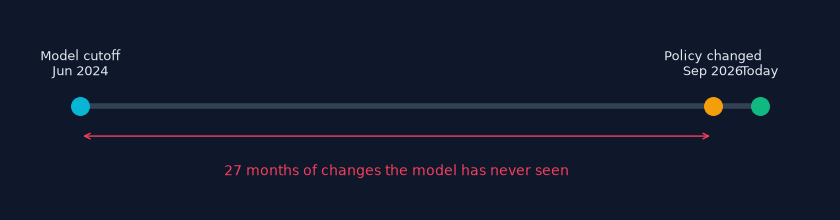

In [187]:
def render_timeline():
    fig, ax = new_fig(8.5, 2.3)
    ax.hlines(0, 0, 29, color=EDGE, linewidth=4)
    pts = [(0, "Model cutoff\nJun 2024", ACC["cyan"]), (27, "Policy changed\nSep 2026", ACC["amber"]), (29, "Today", ACC["green"])]
    for x, label, c in pts:
        ax.scatter([x], [0], s=160, color=c, zorder=3)
        ax.text(x, 0.35, label, ha="center", fontsize=9, color=TXT)
    ax.annotate("", xy=(27, -0.35), xytext=(0, -0.35), arrowprops=dict(arrowstyle="<->", color=ACC["rose"]))
    ax.text(13.5, -0.8, "27 months of changes the model has never seen", ha="center", color=ACC["rose"], fontsize=10)
    ax.set_xlim(-3, 32); ax.set_ylim(-1.2, 1.1); ax.axis("off")
    plt.tight_layout(); plt.show()
render_timeline()

In [188]:
section(4, "Hallucination", "“The model made it up” is not a diagnosis — five different failures hide behind it.", "violet", "👻")

In [189]:
HALL = [
 ("Intrinsic contradiction",  "Answer contradicts the evidence you supplied",       "Evidence says 14 days; answer says 30", "Generation / prompt"),
 ("Extrinsic fabrication",    "Answer adds facts no evidence supports",             "Invents a “cooling-off fee”",           "Generation / prompt"),
 ("Citation hallucination",   "Citation points to a source that doesn't support it", "Cites [S2] but [S2] is about shipping", "Citation validation"),
 ("Retrieval-induced error",  "Wrong evidence retrieved, then faithfully used",     "Retrieved the 2024 policy",             "Retrieval / filtering"),
 ("Synthesis error",          "Right documents, wrong combination",                 "Merges two plans' rules into one",      "Context engineering"),
]
show(table_html(["Type", "What it is", "Example", "Where you fix it"],
                [[f"<b>{a}</b>", b, f"<i>{c}</i>", pill(d, "violet")] for a, b, c, d in HALL], "violet"))

Type,What it is,Example,Where you fix it
Intrinsic contradiction,Answer contradicts the evidence you supplied,Evidence says 14 days; answer says 30,Generation / prompt
Extrinsic fabrication,Answer adds facts no evidence supports,Invents a “cooling-off fee”,Generation / prompt
Citation hallucination,Citation points to a source that doesn't support it,Cites [S2] but [S2] is about shipping,Citation validation
Retrieval-induced error,"Wrong evidence retrieved, then faithfully used",Retrieved the 2024 policy,Retrieval / filtering
Synthesis error,"Right documents, wrong combination",Merges two plans' rules into one,Context engineering


### 🎮 Spot the hallucination
The evidence is fixed. Pick an answer, then classify it. Three of the four answers are broken in *different* ways.

In [190]:
EVIDENCE = {"S1": "Enterprise Annual plans may be cancelled within 14 calendar days of initial purchase.",
            "S2": "Standard shipping takes 3-5 business days."}
ANSWERS = {
 "Answer A": ("Enterprise Annual plans can be cancelled within 30 days of purchase. [S1]", "Intrinsic contradiction", "It contradicts S1 (14 days, not 30)."),
 "Answer B": ("You can cancel within 14 calendar days. A 5% cooling-off fee applies. [S1]", "Extrinsic fabrication", "The fee appears nowhere in the evidence."),
 "Answer C": ("You can cancel within 14 calendar days of purchase. [S2]", "Citation hallucination", "The claim is right, but S2 is about shipping."),
 "Answer D": ("You can cancel within 14 calendar days of purchase. [S1]", "Faithful ✅", "Every claim is supported and correctly cited."),
}
GUESS0 = "— classify it —"

def render_quiz(answer, guess):
    text, truth, why = ANSWERS[answer]
    ev = "".join(f'<div><b style="color:{ACC["cyan"]}">[{k}]</b> {esc(v)}</div>' for k, v in EVIDENCE.items())
    show(f'<div style="background:{CARD};border:1px dashed {EDGE};border-radius:10px;padding:12px 16px;color:{TXT};font-family:{FONT};font-size:14px">'
         f'<div style="color:{MUT};font-size:11px;letter-spacing:.1em;margin-bottom:4px">EVIDENCE</div>{ev}</div>')
    verdict = bubble("bot", "Classify this answer above 👆", "neutral", "your turn") if guess == GUESS0 else (
        bubble("bot", f"✅ <b>{truth}.</b> {why}", "ok", "correct") if guess == truth else
        bubble("bot", f"❌ Not “{esc(guess)}”. Re-read the answer against the evidence.", "bad", "try again"))
    show(bubble("user", "What is the cancellation window for the Enterprise Annual plan?") +
         bubble("bot", esc(text), "neutral", answer) + verdict)

interact_ui({
    "answer": ctl("Dropdown", options=list(ANSWERS), description="Candidate answer"),
    "guess":  ctl("Dropdown", options=[GUESS0] + [v[1] for v in ANSWERS.values()], value=GUESS0, description="Your diagnosis"),
}, render_quiz)

### The grounding rule
Two lines matter more than people expect. **“Say so”** gives the model a legal way out other than inventing. **“State the conflict”** stops it silently choosing the stale version.

In [191]:
GROUNDING_SYSTEM_PROMPT = """You are a grounded enterprise knowledge assistant.

Rules:
1. Use ONLY the evidence below for company-specific claims.
2. If the evidence is insufficient, say exactly: "The available sources do not answer this."
3. If sources conflict, state the conflict and cite both.
4. Cite every material factual claim with its source id, e.g. [S1].
5. Do not add information from your own training data."""

def build_prompt(question, evidence_blocks):
    evidence = "\n\n".join(evidence_blocks)
    return f"{GROUNDING_SYSTEM_PROMPT}\n\nEVIDENCE\n{evidence}\n\nQUESTION\n{question}\n\nANSWER (with citations):"

show(pre_html(build_prompt("What is the cancellation window for the Enterprise Annual plan?",
    ["[S1] Enterprise Cancellation Policy v2026-09: Enterprise Annual plans may be cancelled within 14 calendar days of initial purchase.",
     "[S2] Enterprise Provisioning Rules: cancellation eligibility ends once provisioning has completed."]), "violet"))

In [192]:
section(5, "Context-window limitations", "The context window is a desk, not a warehouse.", "cyan", "🪟")

In [193]:
CONTEXT_WINDOW = 1_000_000

def render_cost(n_docs, tokens_per_doc, price, queries_per_day, k):
    full = n_docs * tokens_per_doc
    rag = k * 400 + 300
    c_full, c_rag = full / 1e6 * price, rag / 1e6 * price
    y_full, y_rag = c_full * queries_per_day * 365, c_rag * queries_per_day * 365
    fits = "✅ fits" if full <= CONTEXT_WINDOW else "❌ does NOT fit"
    show(kpi_html([("Paste everything", f"{full:,} tok", "rose"), ("Retrieve top-k", f"{rag:,} tok", "green"),
                   ("Tokens saved", f"{full / rag:,.0f}×", "indigo"), (f"1M-token window", fits, "amber")]))
    show(kpi_html([("Cost / query (all)", money(c_full), "rose"), ("Cost / query (RAG)", money(c_rag), "green"),
                   ("Per year (all)", money(y_full), "rose"), ("Per year (RAG)", money(y_rag), "green")]))
    fig, ax = new_fig(8.5, 2.2)
    ax.barh(["Retrieve top-k", "Paste everything"], [max(y_rag, 1e-6), max(y_full, 1e-6)], color=[ACC["green"], ACC["rose"]])
    ax.set_xscale("log"); ax.set_xlabel("USD per year (log scale)"); ax.set_title("Annual input-token cost")
    for i, v in enumerate([y_rag, y_full]):
        ax.text(v * 1.15, i, money(v), va="center", fontsize=10, color=TXT)
    ax.set_xlim(right=max(y_full, y_rag, 1) * 30)
    plt.tight_layout(); plt.show()

interact_ui({
    "n_docs":          ctl("IntSlider", value=8000, min=100, max=100000, step=100, description="Documents"),
    "tokens_per_doc":  ctl("IntSlider", value=1200, min=200, max=5000, step=100, description="Tokens / document"),
    "price":           ctl("FloatSlider", value=0.15, min=0.05, max=5.0, step=0.05, description="USD / 1M input tok"),
    "queries_per_day": ctl("IntSlider", value=5000, min=100, max=100000, step=100, description="Queries / day"),
    "k":               ctl("IntSlider", value=5, min=1, max=20, description="Chunks retrieved (k)"),
}, render_cost)
callout("demo", "Drag <b>Documents</b> up to 100,000 and watch the red bar leave the chart. Then ask: <i>“And that is before latency, dilution, version conflicts and security.”</i>")

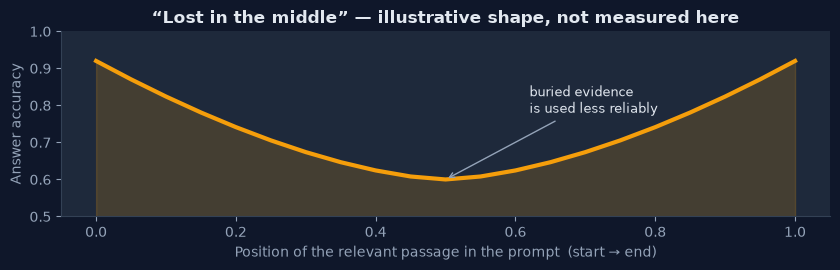

In [194]:
def render_lost_middle():
    xs = [i / 20 for i in range(21)]
    ys = [0.60 + 0.32 * abs(2 * x - 1) ** 1.6 for x in xs]
    fig, ax = new_fig(8.5, 2.8)
    ax.plot(xs, ys, color=ACC["amber"], linewidth=3)
    ax.fill_between(xs, ys, 0.5, color=ACC["amber"], alpha=0.18)
    ax.set_ylim(0.5, 1.0); ax.set_xlabel("Position of the relevant passage in the prompt  (start → end)")
    ax.set_ylabel("Answer accuracy"); ax.set_title("“Lost in the middle” — illustrative shape, not measured here")
    ax.annotate("buried evidence\nis used less reliably", xy=(0.5, 0.60), xytext=(0.62, 0.78), color=TXT, fontsize=9,
                arrowprops=dict(arrowstyle="->", color=MUT))
    plt.tight_layout(); plt.show()
render_lost_middle()
callout("key", "More context is not more signal. A smaller, relevant, <b>permissioned</b> context is cheaper, faster, safer — and easier to debug.")

In [195]:
section(6, "Why RAG?", "An inference-time architecture: find the evidence, then answer from it. Nothing is retrained.", "green", "💡")

In [196]:
show(flow_html([("❓", "1 · Take the query", "indigo"), ("🔎", "2 · Search the knowledge store", "cyan"), ("🎯", "3 · Select evidence", "green"),
                ("🧱", "4 · Build the context", "amber"), ("🤖", "5 · LLM answers from it", "violet"), ("📌", "6 · Return answer + sources", "pink")]))

Formally, with $q$ the query, $K$ the knowledge index and $I$ the instructions:

$$D_q = \text{Retrieve}(q, K) \qquad a = \text{LLM}(q, D_q, I)$$

The rest of the course is making `Retrieve` better and `LLM(...)` more disciplined. Here is the **entire idea in a few lines** — no framework, no vector database. We build a tiny TF-IDF retriever from scratch.

In [197]:
STOP = set("""a an the and or of to in on for with by at from as is are was were be been being it its this that these those
i me my we our you your he she they them his her their do does did how what when where who which why can could should would
will shall may might must have has had not no so if than then there here about into over under also any many much more most
some such only own same too very just up out off again further once all both each few other s t""".split())

def stem(w):
    if len(w) > 4 and w.endswith("ies"):
        w = w[:-3] + "y"
    else:
        for suf in ("ations", "ation", "ing", "ed", "s"):
            if len(w) - len(suf) >= 3 and w.endswith(suf) and not w.endswith("ss"):
                w = w[:-len(suf)]
                break
    if len(w) > 4 and w.endswith("e"): w = w[:-1]
    if len(w) > 4 and w[-1] == w[-2]: w = w[:-1]
    return w

def tokenize(text):
    return [stem(w) for w in re.findall(r"[a-z0-9]+", text.lower()) if w not in STOP]

class TfidfIndex:
    """TF-IDF + cosine similarity in ~15 lines of pure Python (no scikit-learn needed)."""
    def __init__(self, texts, analyzer=tokenize):
        self.analyzer = analyzer
        self.docs = [Counter(analyzer(t)) for t in texts]
        n = len(texts)
        df = Counter(t for d in self.docs for t in d)
        self.idf = {t: math.log((1 + n) / (1 + c)) + 1 for t, c in df.items()}
        self.vecs = [self._vec(d) for d in self.docs]
    def _vec(self, counts):
        v = {t: c * self.idf[t] for t, c in counts.items() if t in self.idf}
        norm = math.sqrt(sum(x * x for x in v.values())) or 1.0
        return {t: x / norm for t, x in v.items()}
    def scores(self, query):
        q = self._vec(Counter(self.analyzer(query)))
        return [sum(w * d.get(t, 0.0) for t, w in q.items()) for d in self.vecs]

mini_docs = [
    "Enterprise Annual plans may be cancelled within 14 calendar days of purchase.",
    "Support is available 24x7 for Enterprise customers via chat and phone.",
    "Invoices are issued on the first business day of each month.",
]
mini_index = TfidfIndex(mini_docs)

def render_mini_rag(question):
    scores = mini_index.scores(question)
    best = max(range(len(scores)), key=lambda i: scores[i])
    rows = ""
    for i, (d, s) in enumerate(zip(mini_docs, scores)):
        win = i == best and s > 0
        rows += (f'<div style="display:flex;gap:12px;align-items:center;background:{CARD};border-radius:10px;padding:10px 14px;margin:6px 0;'
                 f'border:2px solid {ACC["green"] if win else EDGE};color:{TXT};font-family:{FONT};font-size:14px">'
                 f'<div style="min-width:70px;font-weight:800;color:{ACC["green"] if win else MUT}">{s:.2f}</div>{meter(s, 1, "green" if win else "indigo", 110)}'
                 f'<div>{esc(d)}</div>{"<div>🏆</div>" if win else ""}</div>')
    show(bubble("user", esc(question)) + rows)
    if scores[best] > 0:
        ctx = f"[S1] {mini_docs[best]}"
        prompt = build_prompt(question, [ctx])
        show(f'<div style="color:{MUT};font-family:{FONT};font-size:13px;margin-top:8px">What the LLM actually receives:</div>' + pre_html(prompt, "green", 260))
        if LIVE_LLM:
            try: show(bubble("bot", esc(chat(prompt)), "ok", "live LLM answer"))
            except Exception as e: print("⚠️ live call failed:", str(e)[:120])
    else:
        show(bubble("bot", "Nothing matched — a grounded system should say so instead of guessing.", "warn", "no evidence"))

interact_ui({"question": ctl("Text", value="how long do I have to cancel?", description="Ask a question")},
            render_mini_rag, button="Retrieve ▶")
callout("demo", "Try: <i>when can I call support?</i> · <i>when do invoices go out?</i> · <i>what is the CEO's salary?</i> (no match → honest “nothing found”).")
callout("key", "That context is <b>the entire difference between a guess and an answer</b>.")

In [198]:
section(7, "RAG vs fine-tuning", "Fine-tuning changes how a model behaves. RAG changes what it knows right now.", "pink", "⚖️")

In [199]:
rows = [["Best for", "Fresh, private, citable <b>knowledge</b>", "Style, format, tone, narrow <b>behaviour</b>"],
        ["Updating a fact", "✅ edit the document", "❌ retrain / re-tune"],
        ["Citations & audit", "✅ native", "❌ none"],
        ["Per-user permissions", "✅ filter at retrieval", "❌ weights are shared by everyone"],
        ["Deleting data (e.g. GDPR)", "✅ delete from index", "❌ unreliable"],
        ["Upfront cost", "💲 pipeline engineering", "💲💲 data labelling + training runs"],
        ["Per-query cost", "extra retrieval + longer prompt", "can be cheaper (shorter prompts, smaller model)"]]
show(table_html(["Dimension", "🔎 RAG", "🎛 Fine-tuning"], rows, "pink"))

Dimension,🔎 RAG,🎛 Fine-tuning
Best for,"Fresh, private, citable knowledge","Style, format, tone, narrow behaviour"
Updating a fact,✅ edit the document,❌ retrain / re-tune
Citations & audit,✅ native,❌ none
Per-user permissions,✅ filter at retrieval,❌ weights are shared by everyone
Deleting data (e.g. GDPR),✅ delete from index,❌ unreliable
Upfront cost,💲 pipeline engineering,💲💲 data labelling + training runs
Per-query cost,extra retrieval + longer prompt,"can be cheaper (shorter prompts, smaller model)"


### 🎮 Decision wizard
Tick every statement that is true for your project.

In [200]:
RAG_SIGNALS = [("fresh", "Facts change weekly or faster", 2), ("cite", "Answers must cite sources", 2),
               ("perm", "Different users may see different documents", 2), ("priv", "The knowledge is private / proprietary", 1)]
FT_SIGNALS  = [("tone", "I need a consistent tone, format or JSON schema", 2), ("small", "I need a small, fast model for one narrow task", 2),
               ("style", "The base model fails at the *skill*, not at the facts", 2)]

def render_wizard(**ticks):
    rag = sum(w for k, _, w in RAG_SIGNALS if ticks[k]); ft = sum(w for k, _, w in FT_SIGNALS if ticks[k])
    total = max(rag + ft, 1)
    empty = f'<div style="background:{EDGE};width:100%;display:flex;align-items:center;justify-content:center">tick something above</div>' if not (rag + ft) else ""
    lab_r = f"RAG {rag}" if rag else ""
    lab_f = f"FINE-TUNE {ft}" if ft else ""
    show(f'<div style="display:flex;height:34px;border-radius:10px;overflow:hidden;font-family:{FONT};font-weight:800;color:#fff;font-size:13px;margin:8px 0">'
         f'<div style="width:{100*rag/total:.0f}%;background:{ACC["cyan"]};display:flex;align-items:center;justify-content:center">{lab_r}</div>'
         f'<div style="width:{100*ft/total:.0f}%;background:{ACC["pink"]};display:flex;align-items:center;justify-content:center">{lab_f}</div>{empty}</div>')
    if rag + ft == 0:
        return
    if rag >= 2 and ft >= 2:
        msg, tone = "<b>Combine them.</b> RAG supplies the knowledge, a light fine-tune fixes the behaviour — very common in production.", "warn"
    elif rag > ft:
        msg, tone = "<b>Start with RAG.</b> Your problem is knowledge: freshness, privacy, permissions, citations.", "ok"
    else:
        msg, tone = "<b>Consider fine-tuning.</b> Your problem is behaviour, not facts — but check that RAG can't solve it with a better prompt first.", "neutral"
    show(bubble("bot", msg, tone, "recommendation"))

ticks = {k: ctl("Checkbox", value=False, description=d, indent=False) for k, d, _ in RAG_SIGNALS + FT_SIGNALS}
interact_ui(ticks, render_wizard)
callout("key", "<b>Rule of thumb:</b> fine-tune for <i>how</i> the model answers; use RAG for <i>what</i> it answers from.")

In [201]:
section(8, "RAG vs long-context LLMs", "Big windows are great — but they are not a replacement for retrieval.", "sky", "📚")

In [202]:
rows = [["Corpus size", "Small, fixed (one contract, one report)", "Large, growing (wikis, tickets, contracts)"],
        ["Cost per question", "Pays for the whole document every time", "Pays only for the retrieved evidence"],
        ["Freshness", "Re-paste on every change", "Update the index incrementally"],
        ["Permissions", "Everything in the prompt is visible", "Filter before the model sees anything"],
        ["Citations", "Possible, but harder to verify", "Chunk-level source ids built in"],
        ["Debuggability", "Which of 900 pages caused it?", "Inspect exactly what was retrieved"],
        ["Best used when", "One-off deep reading of a single doc", "A living enterprise knowledge base"]]
show(table_html(["", "📚 Long-context", "🔎 RAG"], rows, "sky"))

def render_longctx(corpus_tokens, window, price):
    c_long, c_rag = corpus_tokens / 1e6 * price, 2300 / 1e6 * price
    fits = corpus_tokens <= window
    xs = [10 ** (4 + i * 0.1) for i in range(41)]
    fig, ax = new_fig(8.5, 3.2)
    ax.plot(xs, [x / 1e6 * price for x in xs], color=ACC["rose"], linewidth=3, label="Long-context: send everything")
    ax.axhline(c_rag, color=ACC["green"], linewidth=3, label="RAG: ~2,300 tokens of evidence")
    ax.axvline(window, color=ACC["amber"], linestyle="--", label=f"Context window ({window:,})")
    ax.scatter([corpus_tokens], [c_long], s=120, color="white", zorder=4)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("Corpus size (tokens)"); ax.set_ylabel("USD per question")
    ax.set_title("Cost per question as the corpus grows"); ax.legend(fontsize=8, loc="upper left")
    plt.tight_layout(); plt.show()
    show(kpi_html([("Your corpus", f"{corpus_tokens:,.0f} tok", "indigo"), ("Fits in window?", "✅ yes" if fits else "❌ no", "green" if fits else "rose"),
                   ("Long-context / question", money(c_long), "rose"), ("RAG / question", money(c_rag), "green")]))
    if not fits:
        show(bubble("bot", "The corpus is bigger than the window — <b>retrieval is not optional</b>.", "bad", "verdict"))
    elif c_long > 5 * c_rag:
        show(bubble("bot", f"It fits, but costs <b>{c_long / c_rag:,.0f}×</b> more per question — and permissions, freshness and debugging still favour RAG.", "warn", "verdict"))
    else:
        show(bubble("bot", "Small enough that long-context is perfectly reasonable for a one-off analysis.", "ok", "verdict"))

interact_ui({
    "corpus_tokens": ctl("FloatLogSlider", value=5e5, base=10, min=4, max=8, step=0.1, description="Corpus size (tokens)"),
    "window": ctl("Dropdown", options=[("128K", 128_000), ("200K", 200_000), ("1M", 1_000_000), ("2M", 2_000_000)], value=1_000_000, description="Context window"),
    "price":  ctl("FloatSlider", value=0.15, min=0.05, max=5.0, step=0.05, description="USD / 1M input tok"),
}, render_longctx)
callout("ask", "“If windows reach 10 million tokens, is RAG dead?” — Cost, permissions, freshness and auditability don't go away when the window grows.")

,📚 Long-context,🔎 RAG
Corpus size,"Small, fixed (one contract, one report)","Large, growing (wikis, tickets, contracts)"
Cost per question,Pays for the whole document every time,Pays only for the retrieved evidence
Freshness,Re-paste on every change,Update the index incrementally
Permissions,Everything in the prompt is visible,Filter before the model sees anything
Citations,"Possible, but harder to verify",Chunk-level source ids built in
Debuggability,Which of 900 pages caused it?,Inspect exactly what was retrieved
Best used when,One-off deep reading of a single doc,A living enterprise knowledge base


In [203]:
section(9, "RAG architecture", "Twelve components, two lanes — and a known failure at every one.", "indigo", "🏗️")

In [204]:
COMPONENTS = [  # name, lane, what it does, typical failure, fix
 ("Data sources", "offline", "PDFs, wikis, tickets, databases, APIs", "Stale, duplicated or messy sources", "Ownership + freshness SLAs per source"),
 ("Ingestion & parsing", "offline", "Extract clean text, tables and structure", "Tables flattened, headers lost", "Layout-aware parsers, quality checks"),
 ("Chunking + metadata", "offline", "Split into retrievable units; attach title, version, ACL", "Boundary cuts the answer in half", "Structure-aware chunks, overlap, rich metadata"),
 ("Embedding model", "offline", "Turn each chunk into a vector of meaning", "Domain jargon not captured", "Domain-tuned or hybrid (keyword + vector)"),
 ("Index / vector store", "offline", "Store vectors + metadata for fast search", "Index drifts out of date", "Incremental re-ingest, metadata filters"),
 ("Query understanding", "online", "Rewrite / expand / classify the user's question", "Ambiguous follow-ups (“and for Enterprise?”)", "Rewrite with chat history"),
 ("Retriever + filters", "online", "Find candidates; apply permission and version filters", "Right doc ranked 8th, or leaked", "Hybrid search, pre-filtering"),
 ("Reranker", "online", "Re-score the top-N more carefully", "Adds latency", "Rerank a small N; cache"),
 ("Context builder", "online", "Dedupe, order, label and budget the evidence", "Duplicates, conflicts, overflow", "Token budget, conflict flags"),
 ("LLM generator", "online", "Write the answer from the evidence only", "Ignores evidence, fabricates", "Grounding prompt, abstain path, low temperature"),
 ("Citations & guardrails", "online", "Attach and validate sources; refuse when unsupported", "Citation doesn't support claim", "Automatic citation validation"),
 ("Evaluation & monitoring", "both", "Golden questions, feedback, drift alerts", "Silent quality decay", "Regression suite + dashboards"),
]
LANE_COLOR = {"offline": "cyan", "online": "green", "both": "amber"}

def render_architecture(component):
    names = [c[0] for c in COMPONENTS]
    sel = names.index(component)
    def lane(title, lane_key, color):
        chips = ""
        for i, c in enumerate(COMPONENTS):
            if c[1] != lane_key: continue
            on = i == sel
            chips += (f'<div style="background:{ACC[color] if on else CARD};color:{"#fff" if on else TXT};border:2px solid {ACC[color]};'
                      f'border-radius:10px;padding:8px 12px;font-size:13px;font-weight:700;{"animation:rgpulse 1.8s infinite;" if on else ""}">'
                      f'{i + 1}. {esc(c[0])}</div>')
        return (f'<div style="margin:8px 0"><div style="color:{ACC[color]};font-weight:800;font-size:13px;letter-spacing:.1em;margin-bottom:6px">{title}</div>'
                f'<div style="display:flex;gap:8px;flex-wrap:wrap">{chips}</div></div>')
    show(f'<div style="background:{BG};border:1px solid {EDGE};border-radius:14px;padding:14px 18px;font-family:{FONT}">' +
         lane("OFFLINE · INDEXING (runs when documents change)", "offline", "cyan") +
         lane("ONLINE · QUERY TIME (runs on every question)", "online", "green") +
         lane("CROSS-CUTTING", "both", "amber") + '</div>')
    n, ln, what, fail, fix = COMPONENTS[sel]
    show(f'<div style="background:{CARD};border-radius:14px;padding:16px 22px;margin-top:10px;color:{TXT};font-family:{FONT};border:1px solid {ACC[LANE_COLOR[ln]]}">'
         f'<div style="font-size:20px;font-weight:800;color:{ACC[LANE_COLOR[ln]]}">{sel + 1}. {esc(n)} {pill(ln, LANE_COLOR[ln])}</div>'
         f'<div style="margin-top:8px">🧩 <b>Does:</b> {esc(what)}</div>'
         f'<div style="margin-top:4px">💥 <b>Typically fails when:</b> {esc(fail)}</div>'
         f'<div style="margin-top:4px">🛠 <b>Fix:</b> <span style="color:{ACC["green"]}">{esc(fix)}</span></div></div>')

interact_ui({"component": ctl("Dropdown", options=[c[0] for c in COMPONENTS], value="Chunking + metadata", description="Inspect component")},
            render_architecture)
callout("demo", "Walk the dropdown top to bottom — it doubles as the course roadmap. Every later week is one of these boxes.")

In [205]:
section(10, "RAG pipeline lifecycle", "Offline: prepare the knowledge. Online: use it. Keep the two lanes separate in your head.", "violet", "🔄")

In [206]:
show(f'<div style="color:{ACC["cyan"]};font-weight:800;letter-spacing:.1em;font-family:{FONT};font-size:13px">OFFLINE · INDEXING PIPELINE</div>' +
     flow_html([("📄", "Load", "cyan"), ("✂️", "Chunk", "sky"), ("🏷", "Add metadata", "indigo"), ("🧮", "Embed", "violet"), ("🗄", "Store", "pink")]) +
     f'<div style="color:{ACC["green"]};font-weight:800;letter-spacing:.1em;font-family:{FONT};font-size:13px">ONLINE · QUERY PIPELINE</div>' +
     flow_html([("❓", "Question", "indigo"), ("🔎", "Retrieve + filter", "green"), ("🧱", "Build context", "amber"),
                ("🤖", "Generate", "violet"), ("📌", "Cite & validate", "pink")]))

### 🏢 Our demo knowledge base
Twelve small documents with the metadata real systems need: **department, version, status, and an access level**. Note the two cancellation policies — one is *superseded*. That is a trap on purpose.

In [207]:
KB = [
 dict(id="POL-CAN-2026", title="Enterprise Cancellation Policy", dept="Legal", version="2026-09", status="current", access="internal",
      text="Enterprise Annual plans may be cancelled within 14 calendar days of initial purchase. Cancellation requests must be submitted through the customer portal or by email to the account manager. Once provisioning has completed, the cancellation window closes and the standard termination clause applies. Refunds for approved cancellations are issued to the original payment method within 10 business days."),
 dict(id="POL-CAN-2024", title="Enterprise Cancellation Policy", dept="Legal", version="2024-03", status="superseded", access="internal",
      text="Enterprise Annual plans may be cancelled within 30 calendar days of initial purchase. Requests must be sent by email to the account manager. Refunds are issued within 30 business days."),
 dict(id="SUP-HRS-2026", title="Support Hours and Channels", dept="Support", version="2026-06", status="current", access="public",
      text="Enterprise customers receive 24x7 support through chat and phone. Standard plan customers are supported from 9am to 6pm IST on weekdays by email and chat. Priority one incidents are acknowledged within 15 minutes for Enterprise plans and within 4 hours for Standard plans."),
 dict(id="SLA-ENT-2026", title="Enterprise Uptime SLA", dept="Operations", version="2026-02", status="current", access="public",
      text="The Enterprise platform commits to 99.95 percent monthly uptime. If uptime falls below the commitment, customers receive service credits of 10 percent of the monthly fee for every 0.1 percent shortfall, capped at 50 percent. Credits must be claimed within 30 days of the incident and are applied to the next invoice."),
 dict(id="FIN-EXP-2026", title="Expense Reimbursement Policy", dept="Finance", version="2026-01", status="current", access="finance",
      text="Employees may claim travel and client entertainment expenses up to 150 USD per day without prior approval. Claims above this limit require written approval from a director. Receipts must be uploaded within 30 days of the expense, and reimbursements are paid in the next payroll cycle."),
 dict(id="FIN-INV-2026", title="Invoicing and Payment Terms", dept="Finance", version="2026-04", status="current", access="internal",
      text="Invoices are issued on the first business day of each month. Payment terms are net 30 days from the invoice date. Late payments incur interest of 1.5 percent per month. Enterprise customers may request annual invoicing with a purchase order."),
 dict(id="HR-LEAVE-2026", title="Parental Leave Policy", dept="HR", version="2026-03", status="current", access="hr",
      text="Primary caregivers are entitled to 26 weeks of paid parental leave. Secondary caregivers are entitled to 8 weeks. Leave may be taken in one block or split into two blocks within the first 12 months after the birth or adoption."),
 dict(id="SEC-DATA-2026", title="Data Retention and Security Standard", dept="Security", version="2026-05", status="current", access="internal",
      text="Customer data is encrypted at rest with AES-256 and in transit with TLS 1.3. Production customer data is retained for 90 days after contract termination and then permanently deleted. Access to production data requires multi-factor authentication and is logged and reviewed quarterly."),
 dict(id="PRD-PRC-2026", title="Pricing and Plans", dept="Product", version="2026-07", status="current", access="public",
      text="The Standard plan costs 49 USD per user per month. The Enterprise plan costs 99 USD per user per month and includes single sign-on, audit logs and a dedicated account manager. Annual billing provides a 15 percent discount on both plans."),
 dict(id="SUP-ESC-2026", title="Support Escalation Runbook", dept="Support", version="2026-05", status="current", access="internal",
      text="Tier one agents resolve billing and account questions. Security incidents and suspected data breaches must be escalated to the security on-call engineer immediately. Unresolved tickets are escalated to tier two after 4 working hours and to a team lead after 24 hours."),
 dict(id="ONB-ENT-2026", title="Enterprise Onboarding Guide", dept="Customer Success", version="2026-08", status="current", access="public",
      text="New Enterprise customers are assigned an onboarding specialist and receive a kickoff call within 3 business days of purchase. Single sign-on configuration typically takes 2 days. Provisioning of the workspace completes within 5 business days, after which the customer receives admin credentials."),
 dict(id="TRV-POL-2026", title="Travel Policy", dept="Finance", version="2026-02", status="current", access="internal",
      text="Flights over 6 hours may be booked in premium economy. Hotel stays are limited to 220 USD per night in major cities. All travel must be booked through the company portal at least 14 days in advance whenever possible."),
]
KB_BY_ID = {d["id"]: d for d in KB}
ACCESS_COLOR = {"public": "green", "internal": "cyan", "finance": "amber", "hr": "pink"}
ROLE_LEVELS = {"Guest (public only)": {"public"}, "Support agent": {"public", "internal"},
               "Finance analyst": {"public", "internal", "finance"}, "HR partner": {"public", "internal", "hr"}}

rows = [[f"<code>{d['id']}</code>", d["title"], d["dept"], f"v{d['version']}",
         pill(d["status"], "green" if d["status"] == "current" else "rose"), pill(d["access"], ACCESS_COLOR[d["access"]]),
         f'{len(d["text"].split())} words'] for d in KB]
show(table_html(["ID", "Title", "Dept", "Version", "Status", "Access", "Size"], rows, "violet"))

ID,Title,Dept,Version,Status,Access,Size
POL-CAN-2026,Enterprise Cancellation Policy,Legal,v2026-09,current,internal,58 words
POL-CAN-2024,Enterprise Cancellation Policy,Legal,v2024-03,superseded,internal,30 words
SUP-HRS-2026,Support Hours and Channels,Support,v2026-06,current,public,43 words
SLA-ENT-2026,Enterprise Uptime SLA,Operations,v2026-02,current,public,52 words
FIN-EXP-2026,Expense Reimbursement Policy,Finance,v2026-01,current,finance,46 words
FIN-INV-2026,Invoicing and Payment Terms,Finance,v2026-04,current,internal,40 words
HR-LEAVE-2026,Parental Leave Policy,HR,v2026-03,current,hr,40 words
SEC-DATA-2026,Data Retention and Security Standard,Security,v2026-05,current,internal,42 words
PRD-PRC-2026,Pricing and Plans,Product,v2026-07,current,public,41 words
SUP-ESC-2026,Support Escalation Runbook,Support,v2026-05,current,internal,42 words


### 🔧 Building the engine
Below is the *whole* pipeline in one cell. We open each part in sections 11–13.

* **Embeddings:** with `EURI_EMBEDDING_MODEL` set, chunks and queries are embedded by the **real model** (and cached). Keyword scores come from TF-IDF written from scratch, so you can show *both* worlds and hybrid search. Without a key, a hand-made “concept” layer stands in for the embedding model.
* **Generator:** with a key, the **real LLM** answers from the grounded prompt and abstains by following the rules in it. Without a key, a deterministic extractive stand-in is used.

In [208]:
# ── 1. chunking ─────────────────────────────────────────────────────────────────
def split_sentences(t):
    return [s.strip() for s in re.split(r"(?<=[.!?])\s+", t.strip()) if s.strip()]

def chunk_doc(doc, size=55, overlap=20, mode="sentences"):
    pieces = []                                   # (text, carried_words)
    if mode == "words":
        words, step = doc["text"].split(), max(1, size - overlap)
        for i, start in enumerate(range(0, len(words), step)):
            pieces.append((" ".join(words[start:start + size]), size - step if i else 0))
            if start + size >= len(words): break
    else:
        cur, cur_w, cur_carry = [], 0, 0
        for s in split_sentences(doc["text"]):
            w = len(s.split())
            if cur and cur_w + w > size:
                pieces.append((" ".join(cur), cur_carry))
                carry, cw = [], 0
                for prev in reversed(cur):
                    pw = len(prev.split())
                    if cw + pw > overlap: break
                    carry.insert(0, prev); cw += pw
                cur, cur_w, cur_carry = carry, cw, cw
            cur.append(s); cur_w += w
        if cur: pieces.append((" ".join(cur), cur_carry))
    meta = {k: doc[k] for k in ("title", "dept", "version", "status", "access")}
    return [dict(chunk_id=f"{doc['id']}#{i + 1}", doc_id=doc["id"], text=t, carry=c, **meta) for i, (t, c) in enumerate(pieces)]

# ── 2. a tiny hand-made "concept space" (stand-in for what real embeddings learn) ─
CONCEPTS = [
 "cancel terminate end quit stop unsubscribe discontinue cancellation termination",
 "refund reimburse reimbursement repay",
 "price cost pricing fee charge expensive cheap",
 "hours open opening available 24x7 contact reach call",
 "uptime outage downtime sla unavailable",
 "leave maternity paternity parental baby newborn",
 "delete retention erase purge retain",
 "security breach encrypt encryption hack hacked leak privacy",
 "expense expenses spend spending receipt claim",
 "onboarding setup kickoff provisioning activate",
]
CONCEPT_OF = defaultdict(list)
for gid, grp in enumerate(CONCEPTS):
    for w in grp.split():
        CONCEPT_OF[stem(w)].append(f"§{gid}")

def tokenize_semantic(text):
    toks = tokenize(text)
    return toks + [c for t in toks for c in CONCEPT_OF.get(t, [])]

# ── 3. the index ────────────────────────────────────────────────────────────────
class Index:
    def __init__(self, size=55, overlap=20, mode="sentences"):
        global LIVE_EMBED
        self.chunks = [c for d in KB for c in chunk_doc(d, size, overlap, mode)]
        self.texts = [c["title"] + ". " + c["text"] for c in self.chunks]     # title prepended = "contextual header"
        self.lex = TfidfIndex(self.texts, tokenize)
        self.sem = TfidfIndex(self.texts, tokenize_semantic)                  # offline concept layer
        self.dense = None
        if LIVE_EMBED:
            try:
                self.dense = embed_texts(self.texts)                          # REAL embedding calls (cached)
            except Exception as e:
                print("⚠️ live embeddings failed, using the concept layer:", str(e)[:120]); LIVE_EMBED = False

INDEX = Index()

# ── 4. retrieval ────────────────────────────────────────────────────────────────
def retrieve(index, query, k=3, role="Support agent", only_current=True, mode="hybrid"):
    lex, con = index.lex.scores(query), index.sem.scores(query)
    if index.dense is not None:
        try:
            qv = embed_texts([query])[0]
            sem = [cosine(qv, v) for v in index.dense]
        except Exception as e:
            print("⚠️ live query embedding failed, using the concept layer:", str(e)[:120]); sem = con
    else:
        sem = con
    sc = lex if mode == "keyword" else sem if mode == "semantic" else [(a + b) / 2 for a, b in zip(lex, sem)]
    allowed, hits, hid_perm, hid_old = ROLE_LEVELS[role], [], 0, 0
    for c, s, a, b, g in zip(index.chunks, sc, lex, sem, con):
        if s <= 0: continue
        if c["access"] not in allowed: hid_perm += 1; continue
        if only_current and c["status"] != "current": hid_old += 1; continue
        hits.append(dict(chunk=c, score=s, lex=a, sem=b, gate=(a + g) / 2))
    hits.sort(key=lambda h: -h["score"])
    return hits[:k], dict(hidden_perm=hid_perm, hidden_old=hid_old, candidates=len(hits))

# ── 5. generation (scripted, extractive stand-in) ───────────────────────────────
MIN_SCORE = 0.25          # relevance gate used only by the offline generator
ABSTAIN = "The available sources do not answer this."

def evidence_blocks(hits):
    return [f"[S{i + 1}] ({h['chunk']['title']} v{h['chunk']['version']} · {h['chunk']['dept']}) {h['chunk']['text']}" for i, h in enumerate(hits)]

def approx_tokens(text): return max(1, len(text) // 4)

def _conflict(hits, cited):
    versions = defaultdict(set)
    for i in cited:
        c = hits[i - 1]["chunk"]; versions[c["title"]].add(c["version"])
    for t, v in versions.items():
        if len(v) > 1:
            return f"Sources conflict on “{t}”: versions {' vs '.join('v' + x for x in sorted(v))}. Verify which one is in force."
    return None

def generate(question, hits, index=INDEX, use_live=None):
    """Live LLM when available (it must follow the grounding prompt, incl. abstaining); extractive stand-in otherwise."""
    use_live = LIVE_LLM if use_live is None else (use_live and LIVE_LLM)
    prompt = build_prompt(question, evidence_blocks(hits))
    res = dict(prompt=prompt, tokens=approx_tokens(prompt), cited=[], conflict=None, abstained=False, live=False)
    if use_live and hits:
        try:
            ans = chat(prompt)
            cited = sorted({int(n) for n in re.findall(r"\[S(\d+)\]", ans) if 1 <= int(n) <= len(hits)})
            res.update(answer=ans, live=True, cited=cited, abstained=ABSTAIN.lower()[:30] in ans.lower(), conflict=_conflict(hits, cited))
            return res
        except Exception as e:
            res["live_error"] = str(e)[:120]                          # fall through to the offline generator
    if not hits or hits[0]["gate"] < MIN_SCORE:
        res.update(answer=ABSTAIN, abstained=True); return res
    q = set(tokenize_semantic(question)); idf = index.sem.idf
    picks, seen = [], set()
    for i, h in enumerate(hits[:3]):
        scored = []
        for s in split_sentences(h["chunk"]["text"]):
            st = tokenize_semantic(s)
            scored.append((sum(idf.get(t, 0) for t in q & set(st)) / math.sqrt(len(st) or 1), s))   # length-normalised overlap
        sc, sent = max(scored)
        if sc > 0 and sent not in seen:
            picks.append((sc, i, sent)); seen.add(sent)
    if not picks:
        res.update(answer=ABSTAIN, abstained=True); return res
    top = max(p[0] for p in picks)
    picks = [p for p in picks if p[0] >= 0.75 * top]
    res["answer"] = " ".join(f"{s.rstrip('.')} [S{i + 1}]." for _, i, s in picks)
    res["cited"] = sorted({i + 1 for _, i, _ in picks})
    res["conflict"] = _conflict(hits, res["cited"])
    return res

STALE_MEMORY = [(("cancel", "terminat", "refund"), "You can cancel an Enterprise Annual plan within 30 days of purchase."),
                (("support", "hours", "open"), "Support is available 9am-6pm IST on weekdays."),
                (("price", "cost", "pricing"), "The Enterprise plan costs 79 USD per user per month."),
                (("uptime", "sla"), "The platform guarantees 99.9 percent uptime.")]
def closed_book(question):
    """Live: the real LLM with NO evidence. Offline: a scripted, stale-on-purpose stand-in."""
    if LIVE_LLM:
        try: return chat(question, system="Answer in one or two sentences.", max_tokens=150)
        except Exception: pass
    q = question.lower()
    for keys, ans in STALE_MEMORY:
        if any(k in q for k in keys): return ans
    return "Most companies handle this within 5-7 business days."      # a confident guess

QUESTIONS = [
 "How many days do I have to cancel an Enterprise Annual plan?",
 "How do I terminate my subscription?",
 "What is the daily expense limit without approval?",
 "How many weeks of leave do secondary caregivers get?",
 "When is support available for Enterprise customers?",
 "What uptime does the SLA guarantee and what credits do I get?",
 "How long is customer data kept after a contract ends?",
 "What is the CEO's favourite colour?",
]
print(f"✅ Engine ready · {len(KB)} documents → {len(INDEX.chunks)} chunks · "
      + (f"{len(INDEX.dense[0])}-dim LIVE embeddings" if INDEX.dense else f"vocabulary {len(INDEX.lex.idf)} terms (offline concept layer)"))

✅ Engine ready · 12 documents → 13 chunks · 1536-dim LIVE embeddings


### ▶ Trace one question through the whole lifecycle
Pick a question and a role. Each stage is timed on real work done in this notebook.

In [209]:
def render_trace(question, role):
    t = {}
    t0 = time.perf_counter(); n_docs = len(KB); t["load"] = (time.perf_counter() - t0) * 1000
    t0 = time.perf_counter(); chunks = [c for d in KB for c in chunk_doc(d)]; t["chunk"] = (time.perf_counter() - t0) * 1000
    t0 = time.perf_counter(); idx = Index(); t["embed"] = (time.perf_counter() - t0) * 1000
    t0 = time.perf_counter(); hits, info = retrieve(idx, question, 3, role); t["retrieve"] = (time.perf_counter() - t0) * 1000
    t0 = time.perf_counter(); res = generate(question, hits, idx); t["generate"] = (time.perf_counter() - t0) * 1000
    stages = [("📄", "Load", f"{n_docs} documents", t["load"], "cyan"),
              ("✂️", "Chunk", f"{len(chunks)} chunks", t["chunk"], "sky"),
              ("🧮", "Embed + store", (f"{len(idx.dense[0])}-dim live embeddings × {len(idx.chunks)} chunks (cached after first run)" if idx.dense else f"{len(idx.lex.idf)}-term vocabulary, {len(idx.chunks)} vectors"), t["embed"], "violet"),
              ("🔎", "Retrieve + filter", f"{info['candidates']} candidates · {info['hidden_perm']} hidden by permission · {info['hidden_old']} hidden as superseded → top {len(hits)}", t["retrieve"], "green"),
              ("✍️", "Generate" + (" · live LLM" if res["live"] else ""), ("abstained — no sufficient evidence" if res["abstained"] else f"answer cites {', '.join('S' + str(i) for i in res['cited'])}") + f" · prompt ≈ {res['tokens']} tokens", t["generate"], "amber")]
    body = ""
    for e, n, d, ms, c in stages:
        body += (f'<div style="display:flex;gap:14px;align-items:center;background:{CARD};border-left:6px solid {ACC[c]};border-radius:10px;padding:10px 16px;margin:6px 0;'
                 f'color:{TXT};font-family:{FONT};animation:rgfade .5s ease"><div style="font-size:24px">{e}</div>'
                 f'<div style="flex:1"><b style="color:{ACC[c]}">{n}</b><div style="font-size:13px;color:{MUT}">{esc(d)}</div></div>'
                 f'<div style="font-weight:800">{ms:.1f} ms</div></div>')
    show(body)
    tone = "warn" if res["abstained"] else "ok"
    show(bubble("user", esc(question)) + bubble("bot", esc(res["answer"]), tone, f"final answer · role: {role}"))

interact_ui({
    "question": ctl("Dropdown", options=QUESTIONS, description="Question"),
    "role": ctl("Dropdown", options=list(ROLE_LEVELS), value="Support agent", description="Your role"),
}, render_trace)
callout("demo", "Pick <i>daily expense limit</i> as a <b>Support agent</b> (permission wall → abstains), then switch to <b>Finance analyst</b> (answers). Same question, same index.")

In [210]:
section(11, "Indexing pipeline", "Load → chunk → add metadata → embed → store. Quality is decided here, long before the user asks anything.", "cyan", "📥")

### ✂️ Chunking playground
Chunks are the **unit of retrieval**. Too big → noisy and expensive. Too small → the answer gets cut in half. The <span style="background:#f59e0b55">amber</span> text is **overlap** carried over from the previous chunk.

In [211]:
CHUNK_COLORS = ["indigo", "cyan", "green", "amber", "pink", "violet"]

def render_chunks(doc_id, mode, size, overlap):
    doc = KB_BY_ID[doc_id]
    chunks = chunk_doc(doc, size, overlap, mode)
    body = ""
    for i, c in enumerate(chunks):
        col = ACC[CHUNK_COLORS[i % len(CHUNK_COLORS)]]
        words = c["text"].split()
        carried, rest = " ".join(words[:c["carry"]]), " ".join(words[c["carry"]:])
        carried_html = f'<span style="background:#f59e0b55;border-radius:4px;padding:0 3px">{esc(carried)}</span> ' if carried else ""
        broken = mode == "words" and not c["text"].rstrip().endswith((".", "!", "?"))
        body += (f'<div style="background:{CARD};border-left:6px solid {col};border-radius:10px;padding:12px 16px;margin:8px 0;color:{TXT};font-family:{FONT};'
                 f'font-size:14px;line-height:1.55"><div style="font-size:12px;color:{col};font-weight:800;margin-bottom:4px">CHUNK {i + 1} · {len(words)} words '
                 f'{pill("cut mid-sentence", "rose") if broken else ""}</div>{carried_html}{esc(rest)}</div>')
    show(body)
    sizes = [len(c["text"].split()) for c in chunks]
    show(kpi_html([("Chunks", str(len(chunks)), "indigo"), ("Avg words", f"{sum(sizes) / len(sizes):.0f}", "cyan"),
                   ("Doc words", str(len(doc["text"].split())), "green")]))

interact_ui({
    "doc_id": ctl("Dropdown", options=[(f"{d['id']} — {d['title']}", d["id"]) for d in KB], value="POL-CAN-2026", description="Document"),
    "mode": ctl("Dropdown", options=[("Sentence-aware (recommended)", "sentences"), ("Fixed word window", "words")], value="sentences", description="Strategy"),
    "size": ctl("IntSlider", value=40, min=15, max=90, step=5, description="Chunk size (words)"),
    "overlap": ctl("IntSlider", value=15, min=0, max=30, step=5, description="Overlap (words)"),
}, render_chunks)
callout("demo", "Switch the strategy to <b>Fixed word window</b> and size 25: watch the red <i>“cut mid-sentence”</i> badges appear — that is how an answer gets split across two chunks.")

### 🏷 Metadata and 🧮 embeddings
Each chunk keeps its **metadata** (department, version, status, access level) — that is what makes permission filters, version filters and citations possible later. Then it is turned into a vector. Here is a chunk's “embedding” in our TF-IDF stand-in: its heaviest terms.

In [212]:
def render_embedding(chunk_id):
    idx = [c["chunk_id"] for c in INDEX.chunks].index(chunk_id)
    c, vec = INDEX.chunks[idx], INDEX.lex.vecs[idx]
    meta = " ".join([pill(c["dept"], "indigo"), pill("v" + c["version"], "cyan"), pill(c["status"], "green" if c["status"] == "current" else "rose"),
                     pill("access: " + c["access"], ACCESS_COLOR[c["access"]])])
    show(f'<div style="background:{CARD};border-radius:12px;padding:14px 18px;color:{TXT};font-family:{FONT};font-size:14px"><b>{esc(c["chunk_id"])}</b> · {meta}'
         f'<div style="margin-top:8px;color:{MUT}">{esc(c["text"])}</div></div>')
    if INDEX.dense:
        dv = INDEX.dense[idx][:32]
        fig, ax = new_fig(8.5, 2.8)
        ax.bar(range(len(dv)), dv, color=[ACC["cyan"] if x >= 0 else ACC["rose"] for x in dv])
        ax.set_title(f"Live embedding · first 32 of {len(INDEX.dense[idx])} dimensions"); ax.set_xlabel("dimension")
        plt.tight_layout(); plt.show()
        print("Dense vector from the real embedding model: no single dimension is a word — meaning is spread across all of them.")
        return
    top = sorted(vec.items(), key=lambda kv: -kv[1])[:8]
    fig, ax = new_fig(8.5, 3.0)
    ax.barh([t for t, _ in top][::-1], [w for _, w in top][::-1], color=ACC["violet"])
    ax.set_title(f"Heaviest terms in the vector · {len(vec)} non-zero of {len(INDEX.lex.idf)} dimensions")
    plt.tight_layout(); plt.show()
    print("A real embedding model returns ~1,536 DENSE numbers capturing meaning; this one is SPARSE and word-based. The pipeline step is identical.")

interact_ui({"chunk_id": ctl("Dropdown", options=[c["chunk_id"] for c in INDEX.chunks], value="POL-CAN-2026#1", description="Chunk")}, render_embedding)

In [213]:
section(12, "Retrieval pipeline", "Find the right evidence — and only the evidence this user is allowed to see.", "green", "🔎")

In [214]:
def render_retrieval(preset, custom, mode, k, role, only_current):
    question = custom.strip() or preset
    hits, info = retrieve(INDEX, question, k, role, only_current, mode)
    show(bubble("user", esc(question)))
    if not hits:
        show(bubble("bot", "No chunk scored above zero for this role and mode → a grounded system would abstain here.", "warn", "retrieval result"))
    for rank, h in enumerate(hits, 1):
        c, win = h["chunk"], rank == 1
        show(f'<div style="background:{CARD};border:2px solid {ACC["green"] if win else EDGE};border-radius:12px;padding:12px 16px;margin:6px 0;color:{TXT};font-family:{FONT};animation:rgfade .4s ease">'
             f'<div style="display:flex;gap:10px;align-items:center;flex-wrap:wrap"><b style="font-size:18px;color:{ACC["green"] if win else MUT}">#{rank}</b>'
             f'<b>{esc(c["title"])}</b>{pill("v" + c["version"], "cyan")}{pill(c["status"], "green" if c["status"] == "current" else "rose")}{pill(c["access"], ACCESS_COLOR[c["access"]])}'
             f'<span style="margin-left:auto">{meter(h["score"], 1, "green" if win else "indigo", 120)} <b>{h["score"]:.2f}</b></span></div>'
             f'<div style="color:{MUT};font-size:13px;margin-top:6px">keyword {h["lex"]:.2f} · {"embedding" if INDEX.dense else "concept"} {h["sem"]:.2f} · <code>{esc(c["chunk_id"])}</code></div>'
             f'<div style="font-size:14px;margin-top:6px">{esc(c["text"][:230])}{"…" if len(c["text"]) > 230 else ""}</div></div>')
    notes = []
    if info["hidden_perm"]: notes.append(f"🔒 {info['hidden_perm']} matching chunk(s) hidden — <b>{esc(role)}</b> lacks access")
    if info["hidden_old"]: notes.append(f"🕰 {info['hidden_old']} matching chunk(s) hidden — superseded version")
    if notes: show(f'<div style="color:{ACC["amber"]};font-family:{FONT};font-size:14px;margin-top:6px">{"<br>".join(notes)}</div>')

interact_ui({
    "preset": ctl("Dropdown", options=QUESTIONS, description="Preset question"),
    "custom": ctl("Text", value="", placeholder="…or type your own, then press Enter", description="Custom question"),
    "mode": ctl("Dropdown", options=[("Keyword (TF-IDF)", "keyword"), ("Semantic (live embeddings)" if LIVE_EMBED else "Semantic (offline concept layer)", "semantic"), ("Hybrid", "hybrid")], value="hybrid", description="Retrieval mode"),
    "k": ctl("IntSlider", value=3, min=1, max=6, description="Top-k"),
    "role": ctl("Dropdown", options=list(ROLE_LEVELS), value="Support agent", description="Your role"),
    "only_current": ctl("Checkbox", value=True, description="Only current versions", indent=False),
}, render_retrieval)

In [215]:
callout("demo", "Three live moments: <br>① <i>“How do I terminate my subscription?”</i> — set mode to <b>Keyword</b> (finds nothing: the docs say “cancel”), then <b>Concept</b> (finds it). That is why embeddings exist.<br>"
                "② Untick <b>Only current versions</b> — the 2024 policy appears. <br>③ Switch the <b>role</b> on the expense question.")
callout("warn", ("Semantic mode is using your <b>live embedding model</b>. " if INDEX.dense else "No embedding model configured: semantic mode uses a hand-made concept layer (a toy). ")
        + "Production systems usually <b>combine</b> keyword and vector search (hybrid), exactly as here.")

In [216]:
section(13, "Generation pipeline", "Build a context, instruct the model to stay inside it, and give it a legal way to say “I don't know”.", "amber", "✍️")

In [217]:
def render_generation_demo(question, mode, role, only_current, use_live):
    show(bubble("user", esc(question)))
    if mode == "closed":
        show(bubble("bot", esc(closed_book(question)), "bad", "closed book · " + ("live LLM with NO evidence" if LIVE_LLM else "scripted stand-in") + " · uncited, unverifiable"))
        show(f'<div style="color:{MUT};font-family:{FONT};font-size:13px">No retrieval happened. Nothing to audit, nothing to cite.</div>')
        return
    hits, info = retrieve(INDEX, question, 3, role, only_current, "hybrid")
    res = generate(question, hits, INDEX, use_live)
    tone = "warn" if res["abstained"] else ("warn" if res["conflict"] else "ok")
    tag = "abstained · grounded refusal" if res["abstained"] else ("answer from live LLM" if res["live"] else "grounded answer (offline extractive stand-in)")
    show(bubble("bot", esc(res["answer"]) + (f'<div style="margin-top:8px;color:{ACC["amber"]}">⚠️ {esc(res["conflict"])}</div>' if res["conflict"] else ""), tone, tag))
    if res.get("live_error"): print("⚠️ Live LLM call failed, used offline generator:", res["live_error"])
    src = "".join(f'<div style="margin:4px 0"><b style="color:{ACC["cyan"]}">[S{i}]</b> {esc(h["chunk"]["title"])} v{esc(h["chunk"]["version"])} '
                  f'{pill(h["chunk"]["chunk_id"], "indigo")}</div>' for i, h in enumerate(hits, 1))
    show(f'<div style="background:{CARD};border-radius:10px;padding:10px 16px;color:{TXT};font-family:{FONT};font-size:14px"><b>Sources shown to the user</b>{src or " none"}</div>')
    show(f'<details style="margin-top:10px;font-family:{FONT};color:{TXT}"><summary style="cursor:pointer;color:{ACC["violet"]};font-weight:700">'
         f'📜 Show the exact prompt sent to the LLM (≈ {res["tokens"]} tokens)</summary>{pre_html(res["prompt"], "violet", 300)}</details>')

interact_ui({
    "question": ctl("Dropdown", options=QUESTIONS, description="Question"),
    "mode": ctl("ToggleButtons", options=[("Without RAG", "closed"), ("With RAG", "rag")], value="rag", description="Mode"),
    "role": ctl("Dropdown", options=list(ROLE_LEVELS), value="Support agent", description="Your role"),
    "only_current": ctl("Checkbox", value=True, description="Only current versions", indent=False),
    "use_live": ctl("Checkbox", value=LIVE_LLM, description="Use live LLM", indent=False, disabled=not LIVE_LLM),
}, render_generation_demo)
callout("demo", "Flip <b>Without RAG ↔ With RAG</b> on the cancellation question. Then untick <b>Only current versions</b> — the system now <i>states the conflict</i> instead of silently picking one. Finally ask for the CEO's favourite colour: it abstains.")

In [218]:
section(14, "Grounding and citations", "A citation is a claim about evidence. Check it like any other claim.", "rose", "📌")

In [219]:
CIT_EVIDENCE = {"S1": KB_BY_ID["POL-CAN-2026"]["text"], "S2": KB_BY_ID["FIN-INV-2026"]["text"], "S3": KB_BY_ID["ONB-ENT-2026"]["text"]}

def support_score(sentence, evidence):
    toks = set(tokenize(re.sub(r"\[S\d+\]", " ", sentence)))
    if not toks: return 1.0
    return len(toks & set(tokenize(evidence))) / len(toks)

def validate_answer(answer):
    text = re.sub(r"([.!?])\s*((?:\[S\d+\]\s*)+)", r" \2\1", answer.strip())      # "x. [S1]" -> "x [S1]."
    rows = []
    for sent in split_sentences(text):
        cites = re.findall(r"\[(S\d+)\]", sent)
        if not cites:
            rows.append((sent, "—", 0.0, "warn", "⚠️ uncited claim")); continue
        for cid in cites:
            if cid not in CIT_EVIDENCE:
                rows.append((sent, cid, 0.0, "bad", f"❌ {cid} does not exist")); continue
            sc = support_score(sent, CIT_EVIDENCE[cid])
            if sc >= 0.6:
                rows.append((sent, cid, sc, "ok", "✅ supported"))
            else:
                other = [k for k, v in CIT_EVIDENCE.items() if k != cid and support_score(sent, v) >= 0.6]
                rows.append((sent, cid, sc, "bad", "❌ not supported" + (f" — but {', '.join(other)} does" if other else "")))
    return rows

CIT_EXAMPLES = {
 "✅ Well grounded": "Enterprise Annual plans may be cancelled within 14 calendar days of purchase [S1]. Approved refunds are issued within 10 business days [S1].",
 "❌ Fabricated claim": "Enterprise Annual plans may be cancelled within 14 calendar days of purchase [S1]. A 5% cooling-off fee applies [S1].",
 "❌ Wrong source": "Enterprise Annual plans may be cancelled within 14 calendar days of purchase [S2].",
 "⚠️ Uncited": "Enterprise Annual plans may be cancelled within 14 calendar days of purchase.",
 "❌ Phantom source": "Enterprise Annual plans may be cancelled within 14 calendar days of purchase [S7].",
}

def render_citations(example, custom):
    answer = custom.strip() or CIT_EXAMPLES[example]
    ev = "".join(f'<div style="margin:3px 0"><b style="color:{ACC["cyan"]}">[{k}]</b> <span style="color:{MUT}">{esc(v[:150])}…</span></div>' for k, v in CIT_EVIDENCE.items())
    show(f'<div style="background:{CARD};border:1px dashed {EDGE};border-radius:10px;padding:10px 16px;color:{TXT};font-family:{FONT};font-size:13px">'
         f'<div style="color:{MUT};font-size:11px;letter-spacing:.1em">AVAILABLE EVIDENCE</div>{ev}</div>')
    rows = validate_answer(answer)
    tint = {"ok": ACC["green"], "bad": ACC["rose"], "warn": ACC["amber"]}
    show("".join(bubble("bot", f'<span style="background:{tint[t]}33;border-radius:4px;padding:2px 6px">{esc(s)}</span>', t, f"{verdict}") for s, cid, sc, t, verdict in rows))
    show(table_html(["Claim", "Cited", "Support", "Verdict"],
                    [[esc(s[:90]), cid, f'{meter(sc, 1, "green" if t == "ok" else "rose", 80)} {sc:.0%}', v] for s, cid, sc, t, v in rows], "rose"))
    good = sum(1 for r in rows if r[3] == "ok")
    show(kpi_html([("Citation precision", f"{good}/{len(rows)}", "green" if good == len(rows) else "rose")]))

interact_ui({
    "example": ctl("Dropdown", options=list(CIT_EXAMPLES), description="Example answer"),
    "custom": ctl("Textarea", value="", placeholder="…or paste your own answer using [S1] [S2] [S3] markers", description="Custom answer",
                  layout=W.Layout(width="620px", height="70px") if HAS_WIDGETS else None),
}, render_citations, button="Validate citations ▶")
callout("key", "Production citation checks use the same idea with stronger judges (NLI models or an LLM-as-judge). The principle: <b>never show a citation you haven't verified</b>.")
callout("ask", "A user clicks a citation and the page doesn't support the claim. How much trust did you just lose — in the citation, or in the whole product?")

In [220]:
section(15, "Enterprise use cases", "Wherever answers must be current, private, permissioned and traceable.", "pink", "🏢")

In [221]:
USE_CASES = [
 ("🎧", "Customer-support copilot", "Support", "Help-centre, past tickets, product docs", "Fewer escalations, faster first reply", "Stale answers on policy changes", "Resolution time · deflection rate", "indigo"),
 ("🧑‍💼", "Employee policy assistant", "HR & IT", "HR handbook, IT runbooks, benefits", "Cuts repetitive HR / IT tickets", "Leaking HR or salary data", "Ticket deflection · permission-test pass rate", "pink"),
 ("⚖️", "Contract & legal review", "Legal", "Contracts, clauses, regulations", "Hours saved finding clauses", "Citing a superseded clause", "Clause-retrieval recall · citation accuracy", "violet"),
 ("🏥", "Clinical guideline lookup", "Healthcare", "Guidelines, formularies, protocols", "Consistent, evidence-linked answers", "Any unsupported claim is a safety issue", "Faithfulness · abstention correctness", "rose"),
 ("📈", "Financial research & compliance", "Finance", "Filings, research notes, policies", "Faster analyst research", "Mixing figures from different periods", "Numeric accuracy · source freshness", "amber"),
 ("🛠", "Developer docs assistant", "Engineering", "API docs, runbooks, code, incidents", "Faster onboarding and on-call", "Answers for the wrong version of an API", "Time-to-answer · version correctness", "cyan"),
 ("🤝", "Sales enablement & RFPs", "Sales", "Past proposals, product sheets, pricing", "Faster RFP drafts", "Quoting outdated pricing", "Draft acceptance rate · price accuracy", "green"),
 ("🏭", "Maintenance manuals", "Manufacturing", "Manuals, work orders, safety notices", "Shorter downtime", "Skipping a safety warning", "First-fix rate · safety-note recall", "sky"),
]
DOMAINS = ["All"] + sorted({u[2] for u in USE_CASES})

def render_usecases(domain):
    items = [u for u in USE_CASES if domain in ("All", u[2])]
    cards = []
    for e, name, dom, src, value, risk, metric, c in items:
        body = (f'<div style="margin:6px 0">{pill(dom, c)}</div><div>📚 <b>Knowledge:</b> {src}</div><div>✅ <b>Value:</b> {value}</div>'
                f'<div style="color:{ACC["rose"]}">🚨 <b>Key risk:</b> {risk}</div><div style="color:{MUT}">📏 <b>Measure:</b> {metric}</div>')
        cards.append((e, name, body, c))
    show(cards_html(cards, cols=2))

interact_ui({"domain": ctl("Dropdown", options=DOMAINS, value="All", description="Domain")}, render_usecases)
callout("key", "Notice the pattern: every “key risk” is one of the limitations from Section 2 — and every “measure” maps to a component from Section 9.")

In [222]:
section("🎬", "Live playground", "Everything together: ask your own question, switch roles, and watch the guardrails work.", "indigo", "🎬")

In [223]:
def render_playground(question, role, k, only_current):
    if not question.strip():
        show(bubble("bot", "Type a question above and press the button.", "neutral", "assistant")); return
    t0 = time.perf_counter()
    hits, info = retrieve(INDEX, question, k, role, only_current, "hybrid")
    res = generate(question, hits, INDEX)
    ms = (time.perf_counter() - t0) * 1000
    tone = "warn" if (res["abstained"] or res["conflict"]) else "ok"
    chips = "".join(pill(f"[S{i}] {h['chunk']['title']} v{h['chunk']['version']}", "cyan") + " " for i, h in enumerate(hits, 1))
    extra = (f'<div style="margin-top:8px;color:{ACC["amber"]}">⚠️ {esc(res["conflict"])}</div>' if res["conflict"] else "")
    meta = f'<div style="margin-top:10px;font-size:12px;color:{MUT}">⏱ {ms:.1f} ms · 🔒 {info["hidden_perm"]} hidden by permission · 🕰 {info["hidden_old"]} superseded hidden</div>'
    show(bubble("user", esc(question)) +
         bubble("bot", esc(res["answer"]) + extra + (f'<div style="margin-top:10px">{chips}</div>' if hits and not res["abstained"] else "") + meta,
                tone, "RAG assistant"))

interact_ui({
    "question": ctl("Text", value="How many days do I have to cancel an Enterprise Annual plan?", description="Your question"),
    "role": ctl("Dropdown", options=list(ROLE_LEVELS), value="Support agent", description="Your role"),
    "k": ctl("IntSlider", value=3, min=1, max=5, description="Top-k"),
    "only_current": ctl("Checkbox", value=True, description="Only current versions", indent=False),
}, render_playground, button="Ask ▶")
callout("demo", "Invite the audience to type questions. Good ones: <i>how long is data retained</i> · <i>when is support available</i> · <i>who is our CEO</i> · <i>what is the parental leave policy</i> (try as Guest, then HR partner).")

In [224]:
show(f'<div style="font-family:{FONT};font-size:22px;font-weight:800;color:{TXT};margin:24px 0 6px">🎯 What to remember</div>' + cards_html([
 ("🧠", "LLMs predict tokens", f'<div style="color:{MUT}">Fluent is not true. Knowledge is frozen in weights.</div>', "indigo"),
 ("🚧", "Limits are a checklist", f'<div style="color:{MUT}">Cutoff · hallucination · privacy · context · provenance · access · cost.</div>', "rose"),
 ("💡", "RAG = evidence at query time", f'<div style="color:{MUT}">Retrieve → build context → answer from it → cite.</div>', "green"),
 ("⚖️", "Knowledge vs behaviour", f'<div style="color:{MUT}">RAG for what it knows. Fine-tuning for how it behaves.</div>', "pink"),
 ("🔄", "Two lanes", f'<div style="color:{MUT}">Offline indexing, online querying. Most quality is decided offline.</div>', "violet"),
 ("📌", "Verify, don't trust", f'<div style="color:{MUT}">Filter by role and version, abstain when unsure, validate every citation.</div>', "amber"),
], cols=3) +
 f'<div style="background:linear-gradient(120deg,#6366f1,#ec4899);border-radius:16px;padding:22px 28px;color:#fff;font-family:{FONT};margin-top:12px">'
 f'<div style="font-size:12px;letter-spacing:.2em;text-transform:uppercase;opacity:.85">Up next</div>'
 f'<div style="font-size:22px;font-weight:800">Indexing in depth — parsing, chunking strategies, embeddings and vector stores</div>'
 f'<div style="opacity:.9;margin-top:4px">Questions? Try breaking the playground above.</div></div>')